# ARTI 502 — Traffic Sign Recognition
## CNN & YOLOv8n-cls Optimization

**Models:** Custom CNN and YOLOv8n-cls  |  **Dataset:** GTSRB (43 classes)

The notebook presents baseline performance, hyperparameter experiments, key comparisons, and validation examples for both models. All optimization decisions use validation data; the test set is reserved for final evaluation.

## 1. Imports & Environment Setup

In [30]:
import os
import random
import time
import gc
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks

from PIL import Image

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

from google.colab import drive

%pip -q install ultralytics kagglehub

import kagglehub
from ultralytics import YOLO

In [31]:
SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# Display library versions and GPU availability
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
print("Random Seed:", SEED)

TensorFlow: 2.21.0
GPU: []
Random Seed: 42


## 2. Project Paths

In [32]:
# Mount Google Drive to access project files
drive.mount("/content/drive")
BASE = "/content/drive/MyDrive/ARTI502_Project"

# Define dataset, model, and results directories
DATA_DIR = os.path.join(BASE, "data")
MODELS_DIR = os.path.join(BASE, "models")
RESULTS_DIR = os.path.join(BASE, "results")

# Define optimization experiment directories
OPT_MODELS = os.path.join(MODELS_DIR, "optimization")
OPT_RESULTS = os.path.join(RESULTS_DIR, "optimization")

# Create optimization directories if they do not exist
os.makedirs(OPT_MODELS, exist_ok=True)
os.makedirs(OPT_RESULTS, exist_ok=True)

# Verify that the required project files exist
required_files = {
    "Train Split": os.path.join(DATA_DIR, "train_split.csv"),
    "Validation Split": os.path.join(DATA_DIR, "val_split.csv"),
    "Test Split": os.path.join(DATA_DIR, "test_split.csv"),
    "CNN Baseline": os.path.join(MODELS_DIR, "model1_best.keras"),
    "YOLO Baseline": os.path.join(MODELS_DIR, "model2.pt")
}

for name, path in required_files.items():
    print(f"{name}: {'Found' if os.path.isfile(path) else 'Missing'}")

print("\nOptimization Models:", OPT_MODELS)
print("Optimization Results:", OPT_RESULTS)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Train Split: Found
Validation Split: Found
Test Split: Found
CNN Baseline: Found
YOLO Baseline: Found

Optimization Models: /content/drive/MyDrive/ARTI502_Project/models/optimization
Optimization Results: /content/drive/MyDrive/ARTI502_Project/results/optimization


## 3. Dataset Loading

In [33]:
# Load the predefined dataset splits
train_df = pd.read_csv(os.path.join(DATA_DIR, "train_split.csv"))
val_df = pd.read_csv(os.path.join(DATA_DIR, "val_split.csv"))
test_df = pd.read_csv(os.path.join(DATA_DIR, "test_split.csv"))

# Display the number of samples in each split
print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

# Display the number of classes and dataset columns
print("\nNumber of classes:", train_df["ClassId"].nunique())
print("Dataset columns:", train_df.columns.tolist())

# Display the first five samples
display(train_df.head())

Training samples: 31350
Validation samples: 7859
Testing samples: 12630

Number of classes: 43
Dataset columns: ['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path', 'ClassName', 'TrackGroup']


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path,ClassName,TrackGroup
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png,Dangerous curve right,00020_00000
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png,Dangerous curve right,00020_00000
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png,Dangerous curve right,00020_00000
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png,Dangerous curve right,00020_00000
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png,Dangerous curve right,00020_00000


## 4. Dataset Verification

In [34]:
# Check missing values and duplicate image paths
for name, df in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    print(f"{name}:")
    print("Missing values:", df.isnull().sum().sum())
    print("Duplicate paths:", df["Path"].duplicated().sum())
    print("Number of classes:", df["ClassId"].nunique())
    print()

# Check image overlap between dataset splits
train_paths = set(train_df["Path"])
val_paths = set(val_df["Path"])
test_paths = set(test_df["Path"])

print("Train / Validation overlap:", len(train_paths & val_paths))
print("Train / Test overlap:", len(train_paths & test_paths))
print("Validation / Test overlap:", len(val_paths & test_paths))

# Check track group overlap between training and validation
train_groups = set(train_df["TrackGroup"])
val_groups = set(val_df["TrackGroup"])

print("Train / Validation track overlap:", len(train_groups & val_groups))

# Verify class consistency across all splits
train_classes = set(train_df["ClassId"])
val_classes = set(val_df["ClassId"])
test_classes = set(test_df["ClassId"])

print("Same classes across splits:", train_classes == val_classes == test_classes)

Train:
Missing values: 0
Duplicate paths: 0
Number of classes: 43

Validation:
Missing values: 0
Duplicate paths: 0
Number of classes: 43

Test:
Missing values: 0
Duplicate paths: 0
Number of classes: 43

Train / Validation overlap: 0
Train / Test overlap: 0
Validation / Test overlap: 0
Train / Validation track overlap: 0
Same classes across splits: True


## 5. Dataset Access and Visualization

In [35]:
# Download GTSRB and locate the image directory
dataset_path = kagglehub.dataset_download("meowmeowmeowmeowmeow/gtsrb-german-traffic-sign")
DATASET_ROOT = Path(dataset_path)

# Verify that a training image exists
sample_path = DATASET_ROOT / train_df.iloc[0]["Path"]

print("Dataset Root:", DATASET_ROOT)
print("Sample Image:", sample_path)
print("Image Exists:", sample_path.is_file())

Using Colab cache for faster access to the 'gtsrb-german-traffic-sign' dataset.
Dataset Root: /kaggle/input/gtsrb-german-traffic-sign
Sample Image: /kaggle/input/gtsrb-german-traffic-sign/Train/20/00020_00000_00000.png
Image Exists: True


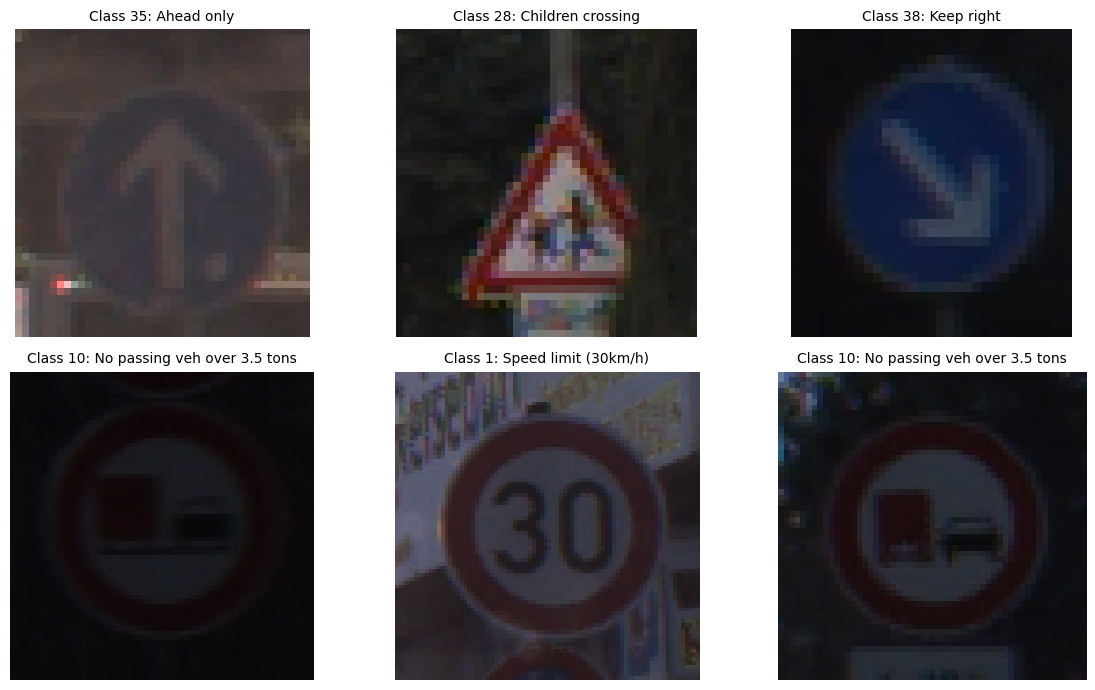

In [36]:
# Display random samples from the GTSRB dataset
sample_df = train_df.sample(n=6, random_state=SEED)

fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for ax, (_, row) in zip(axes.flat, sample_df.iterrows()):
    image_path = DATASET_ROOT / row["Path"]

    with Image.open(image_path) as img:
        image = img.convert("RGB")

    ax.imshow(image)
    ax.set_title(f"Class {row['ClassId']}: {row['ClassName']}", fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 6. Model 1 — Custom CNN Optimization

### 6.1 Original CNN Inspection

In [37]:
# Load the original trained CNN model
MODEL1_PATH = os.path.join(MODELS_DIR, "model1_best.keras")
cnn_baseline = tf.keras.models.load_model(MODEL1_PATH)

# Display model architecture and parameter count
cnn_baseline.summary()
print("\nTotal Parameters:", cnn_baseline.count_params())

Model: "Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │         5,547 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,083,203 (4.13 MB)

 Trainable params: 361,067 (1.38 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 722,136 (2.75 MB)


Total Parameters: 361067


### 6.2 Original CNN Validation Evaluation

In [38]:
# Prepare validation images using the model input size
IMG_SIZE = tuple(cnn_baseline.input_shape[1:3])

def load_cnn_images(df):
    images = []
    labels = []

    for _, row in df.iterrows():
        image_path = DATASET_ROOT / row["Path"]

        image = tf.io.read_file(str(image_path))
        image = tf.image.decode_image(
            image, channels=3, expand_animations=False
        )
        image = tf.image.resize(image, IMG_SIZE)
        image = tf.cast(image, tf.float32) / 255.0

        images.append(image.numpy())
        labels.append(int(row["ClassId"]))

    return np.array(images), np.array(labels)

# Load validation data only
X_val, y_val = load_cnn_images(val_df)

# Evaluate the baseline model on validation data
val_loss, val_accuracy = cnn_baseline.evaluate(
    X_val, y_val,
    batch_size=32,
    verbose=1
)

print(f"\nBaseline Validation Accuracy: {val_accuracy:.4f}")
print(f"Baseline Validation Loss: {val_loss:.4f}")
print(f"Total Parameters: {cnn_baseline.count_params():,}")

246/246 ━━━━━━━━━━━━━━━━━━━━ 9s 32ms/step - accuracy: 0.9598 - loss: 0.1827

Baseline Validation Accuracy: 0.9598
Baseline Validation Loss: 0.1827
Total Parameters: 361,067


### 6.3 CNN Training Pipeline

In [39]:
# Define the original CNN configuration
CNN_BASELINE = {
    "image_size": (32, 32),
    "batch_size": 32,
    "learning_rate": 0.001,
    "optimizer": "Adam",
    "epochs": 25,
    "dropout": 0.4,
    "patience": 5,
    "num_classes": 43,
    "augmentation": False
}

# Create experiments by changing one parameter at a time
CNN_EXP1 = {**CNN_BASELINE, "learning_rate": 0.0003}
CNN_EXP2 = {**CNN_BASELINE, "batch_size": 64}
CNN_EXP3 = {**CNN_BASELINE, "dropout": 0.3}
CNN_EXP4 = {**CNN_BASELINE, "augmentation": True}

# Store all experiment configurations

CNN_EXPERIMENTS = {
    "Baseline": CNN_BASELINE,
    "EXP1": CNN_EXP1,
    "EXP2": CNN_EXP2,
    "EXP3": CNN_EXP3,
    "EXP4": CNN_EXP4
}

# Display configurations for verification
for name, config in CNN_EXPERIMENTS.items():
    print(
        f"{name}: "
        f"LR={config['learning_rate']}, "
        f"Batch={config['batch_size']}, "
        f"Dropout={config['dropout']}, "
        f"Augmentation={config['augmentation']}"
    )

Baseline: LR=0.001, Batch=32, Dropout=0.4, Augmentation=False
EXP1: LR=0.0003, Batch=32, Dropout=0.4, Augmentation=False
EXP2: LR=0.001, Batch=64, Dropout=0.4, Augmentation=False
EXP3: LR=0.001, Batch=32, Dropout=0.3, Augmentation=False
EXP4: LR=0.001, Batch=32, Dropout=0.4, Augmentation=True


In [40]:
# Build CNN using the original model architecture
def build_cnn(config):

    model = models.Sequential([
        layers.Input(shape=(*config["image_size"], 3)),

        layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(config["dropout"]),

        layers.Dense(config["num_classes"], activation="softmax")

    ], name="Custom_CNN")

    # Compile the model with the experiment learning rate
    model.compile(
        optimizer=optimizers.Adam(
            learning_rate=config["learning_rate"]
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


# Verify model creation using baseline settings
test_model = build_cnn(CNN_BASELINE)

print("Model Parameters:", test_model.count_params())
print("Original Parameters:", cnn_baseline.count_params())
print("Architecture Matches:",
      test_model.count_params() == cnn_baseline.count_params())

del test_model

Model Parameters: 361067
Original Parameters: 361067
Architecture Matches: True


In [41]:
# Load training images using the same validation preprocessing
X_train, y_train = load_cnn_images(train_df)

# Display training and validation data shapes
print("Training Images:", X_train.shape)
print("Training Labels:", y_train.shape)
print("Validation Images:", X_val.shape)
print("Validation Labels:", y_val.shape)

# Verify image dimensions and pixel value ranges
print("\nImage Shape:", X_train.shape[1:])
print("Pixel Range:", X_train.min(), "to", X_train.max())

# Verify that image and label counts match
assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)

print("\nCNN Training Data Ready!")

Training Images: (31350, 32, 32, 3)
Training Labels: (31350,)
Validation Images: (7859, 32, 32, 3)
Validation Labels: (7859,)

Image Shape: (32, 32, 3)
Pixel Range: 0.0 to 1.0

CNN Training Data Ready!


#### 6.3.1 Training Function

The same training procedure is used for new CNN experiments. Previously completed checkpoints are reused.

In [42]:
def train_cnn_tuning(name, config):

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    model = build_cnn(config)

    augmentation_type = config["augmentation"]

    augmentation_layers = []

    if augmentation_type in ["rotation", True]:
        augmentation_layers.append(
            layers.RandomRotation(0.05, seed=SEED)
        )

    if augmentation_type in ["zoom", True]:
        augmentation_layers.append(
            layers.RandomZoom(0.1, seed=SEED)
        )

    if augmentation_type in ["translation", True]:
        augmentation_layers.append(
            layers.RandomTranslation(
                0.1, 0.1, seed=SEED
            )
        )

    train_data = tf.data.Dataset.from_tensor_slices(
        (X_train, y_train)
    )

    train_data = train_data.shuffle(
        len(X_train),
        seed=SEED
    ).batch(config["batch_size"])

    if augmentation_layers:

        augmentation = tf.keras.Sequential(
            augmentation_layers
        )

        train_data = train_data.map(
            lambda x, y: (
                augmentation(x, training=True), y
            ),
            num_parallel_calls=1
        )

    train_data = train_data.prefetch(tf.data.AUTOTUNE)

    val_data = tf.data.Dataset.from_tensor_slices(
        (X_val, y_val)
    ).batch(
        config["batch_size"]
    ).prefetch(tf.data.AUTOTUNE)

    model_path = os.path.join(
        OPT_MODELS,
        f"{name}.keras"
    )

    training_callbacks = [
        callbacks.EarlyStopping(
            monitor="val_loss",
            patience=config["patience"],
            restore_best_weights=True
        ),
        callbacks.ModelCheckpoint(
            model_path,
            monitor="val_loss",
            save_best_only=True
        )
    ]

    start_time = time.time()

    history = model.fit(
        train_data,
        validation_data=val_data,
        epochs=config["epochs"],
        callbacks=training_callbacks,
        verbose=0
    )

    training_time = time.time() - start_time

    val_loss, val_accuracy = model.evaluate(
        val_data,
        verbose=0
    )

    result = {
        "Experiment": name,
        "Validation Accuracy": val_accuracy,
        "Validation Loss": val_loss,
        "Training Time (sec)": training_time,
        "Parameters": model.count_params(),
        "Learning Rate": config["learning_rate"],
        "Batch Size": config["batch_size"],
        "Dropout": config["dropout"],
        "Augmentation": augmentation_type
    }

    pd.DataFrame([result]).to_csv(
        os.path.join(
            OPT_RESULTS,
            f"{name}_results.csv"
        ),
        index=False
    )

    print(
        f"{name}: "
        f"Accuracy={val_accuracy:.4f}, "
        f"Loss={val_loss:.4f}, "
        f"Time={training_time / 60:.2f} min"
    )

    return result, history

### 6.4 CNN Baseline

Load the saved baseline model and metrics; rerun training only when required.

In [43]:
# Prevent accidental retraining and checkpoint overwrites
RUN_MISSING_EXPERIMENTS = False

def load_or_train(name, config):
    result_file = os.path.join(OPT_RESULTS, f"{name}_results.csv")
    model_file = os.path.join(OPT_MODELS, f"{name}.keras")
    if os.path.isfile(result_file) and os.path.isfile(model_file):
        row = pd.read_csv(result_file).iloc[0].to_dict()
        print(f"Loaded: {name}")
        return row
    if not RUN_MISSING_EXPERIMENTS:
        raise FileNotFoundError(
            f"Missing saved result or model for {name}. "
            "Check Google Drive, or explicitly enable RUN_MISSING_EXPERIMENTS."
        )
    result, _ = train_cnn_tuning(name, config)
    return result

baseline_result = load_or_train("CNN_Baseline", CNN_BASELINE)
display(pd.DataFrame([baseline_result]))

Loaded: CNN_Baseline


,Experiment,Validation Accuracy,Validation Loss,Training Time (sec),Parameters,Learning Rate,Batch Size,Dropout,Augmentation
0,CNN_Baseline,0.957246,0.20008,78.056828,361067,0.001,32,0.4,False


### 6.5 Hyperparameter Sensitivity

Vary one setting at a time and compare validation results.

In [44]:
# Define candidate values for each hyperparameter

CNN_SEARCH_SPACE = {
    "Learning Rate": {
        "key": "learning_rate",
        "values": [0.0001, 0.0005, 0.001, 0.002, 0.005]
    },
    "Batch Size": {
        "key": "batch_size",
        "values": [8, 16, 32, 64, 128]
    },
    "Dropout": {
        "key": "dropout",
        "values": [0.1, 0.3, 0.4, 0.5, 0.7]
    }
}

# Define augmentation strategies

AUGMENTATION_OPTIONS = {
    "None": False,
    "Rotation": "rotation",
    "Zoom": "zoom",
    "Translation": "translation",
    "Combined": True
}

In [45]:
# Match previously completed runs to their original configurations
HISTORICAL_CONFIGS = {
    "CNN_Baseline": CNN_BASELINE,
    "CNN_EXP1": {**CNN_BASELINE, "learning_rate": 0.0003},
    "CNN_EXP2": {**CNN_BASELINE, "batch_size": 64},
    "CNN_EXP3": {**CNN_BASELINE, "dropout": 0.3},
    "CNN_EXP4": {**CNN_BASELINE, "augmentation": True},
}

def matching_historical_name(config):
    keys = ("learning_rate", "batch_size", "dropout", "augmentation")
    for name, old in HISTORICAL_CONFIGS.items():
        if all(config[key] == old[key] for key in keys):
            return name
    return None

# Load saved sensitivity results when available
sensitivity_file = os.path.join(OPT_RESULTS, "CNN_Sensitivity_Results.csv")
if os.path.isfile(sensitivity_file):
    sensitivity_df = pd.read_csv(sensitivity_file, keep_default_na=False)
    sensitivity_df["Tested Value"] = sensitivity_df["Tested Value"].replace({"None": "None"})
    print("Loaded complete sensitivity table from Drive.")
else:
    records = []
    for group, search in CNN_SEARCH_SPACE.items():
        for index, value in enumerate(search["values"], 1):
            config = {**CNN_BASELINE, search["key"]: value}
            name = matching_historical_name(config) or f"CNN_{search['key']}_V{index}"
            row = load_or_train(name, config)
            records.append({**row, "Group": group, "Tested Value": value})
    for strategy, value in AUGMENTATION_OPTIONS.items():
        config = {**CNN_BASELINE, "augmentation": value}
        name = matching_historical_name(config) or f"CNN_AUG_{strategy}"
        row = load_or_train(name, config)
        records.append({**row, "Group": "Augmentation", "Tested Value": strategy})
    sensitivity_df = pd.DataFrame(records)
    sensitivity_df.to_csv(sensitivity_file, index=False)

for col in ("Validation Accuracy", "Validation Loss", "Training Time (sec)"):
    sensitivity_df[col] = pd.to_numeric(sensitivity_df[col])
assert len(sensitivity_df) == 20, "Expected 20 sensitivity rows."
display(sensitivity_df[["Group", "Tested Value", "Validation Accuracy", "Validation Loss", "Training Time (sec)"]])

Loaded complete sensitivity table from Drive.


,Group,Tested Value,Validation Accuracy,Validation Loss,Training Time (sec)
0,Learning Rate,0.0001,0.899478,0.346981,117.546494
1,Learning Rate,0.0005,0.955211,0.177325,71.700027
2,Learning Rate,0.001,0.957246,0.200080,78.056828
3,Learning Rate,0.002,0.941850,0.241212,49.548542
4,Learning Rate,0.005,0.057259,3.491486,46.078870
5,Batch Size,8,0.949739,0.216443,182.404814
6,Batch Size,16,0.959537,0.197013,108.538615
7,Batch Size,32,0.957246,0.200080,78.056828
8,Batch Size,64,0.948212,0.187999,54.634942
9,Batch Size,128,0.946176,0.203120,53.705094


### 6.6 Best Hyperparameter Selection

Select the value with the lowest validation loss in each group.

In [46]:
# Select the minimum-validation-loss configuration in each group
best_settings = sensitivity_df.loc[
    sensitivity_df.groupby("Group")["Validation Loss"].idxmin()
].sort_values("Group").reset_index(drop=True)

display(best_settings[["Group", "Tested Value", "Validation Accuracy", "Validation Loss"]])

# Build the combined configuration from the selected values
selected = dict(zip(best_settings["Group"], best_settings["Tested Value"]))
augmentation_mapping = {
    "None": False, "Rotation": "rotation", "Zoom": "zoom",
    "Translation": "translation", "Combined": True
}
CNN_COMBINED = {
    **CNN_BASELINE,
    "learning_rate": float(selected["Learning Rate"]),
    "batch_size": int(selected["Batch Size"]),
    "dropout": float(selected["Dropout"]),
    "augmentation": augmentation_mapping[selected["Augmentation"]]
}
print("Selected combined configuration:", CNN_COMBINED)

best_settings.to_csv(os.path.join(OPT_RESULTS, "CNN_Best_Hyperparameters.csv"), index=False)

,Group,Tested Value,Validation Accuracy,Validation Loss
0,Augmentation,Rotation,0.965136,0.151952
1,Batch Size,64,0.948212,0.187999
2,Dropout,0.7,0.968062,0.136336
3,Learning Rate,0.0005,0.955211,0.177325


Selected combined configuration: {'image_size': (32, 32), 'batch_size': 64, 'learning_rate': 0.0005, 'optimizer': 'Adam', 'epochs': 25, 'dropout': 0.7, 'patience': 5, 'num_classes': 43, 'augmentation': 'rotation'}


### 6.7 Combined Optimization

Evaluate the combination of selected values using its saved result. Individual winners do not necessarily perform best together.

In [47]:
# Load the completed combined run without retraining
combined_result = load_or_train("CNN_Combined_Final", CNN_COMBINED)
combined_history = None

display(pd.DataFrame([combined_result]))

Loaded: CNN_Combined_Final


,Experiment,Validation Accuracy,Validation Loss,Training Time (sec),Parameters,Learning Rate,Batch Size,Dropout,Augmentation
0,CNN_Combined_Final,0.961191,0.156711,171.497768,361067,0.0005,64,0.7,rotation


### 6.8 Results & Figures

Compare validation accuracy and loss for the baseline, individual changes, and combined experiment.

In [48]:
# Collect unique experiment results and rank by validation loss
all_cnn_results = pd.concat([
    pd.DataFrame([baseline_result]),
    sensitivity_df.drop(columns=["Group", "Tested Value"]),
    pd.DataFrame([combined_result])
], ignore_index=True).drop_duplicates(subset="Experiment", keep="last")
all_cnn_results = all_cnn_results.sort_values("Validation Loss").reset_index(drop=True)
all_cnn_results.to_csv(os.path.join(OPT_RESULTS, "CNN_All_Optimization_Results.csv"), index=False)
display(all_cnn_results[["Experiment", "Validation Accuracy", "Validation Loss", "Training Time (sec)"]])

,Experiment,Validation Accuracy,Validation Loss,Training Time (sec)
0,CNN_dropout_V5,0.968062,0.136336,68.974257
1,CNN_AUG_Rotation,0.965136,0.151952,94.698843
2,CNN_Combined_Final,0.961191,0.156711,171.497768
3,CNN_EXP4,0.959919,0.168254,232.894693
4,CNN_learning_rate_V2,0.955211,0.177325,71.700027
5,CNN_EXP3,0.949994,0.185035,47.663369
6,CNN_dropout_V4,0.954574,0.187049,56.422670
7,CNN_EXP2,0.948212,0.187999,54.634942
8,CNN_batch_size_V2,0.959537,0.197013,108.538615
9,CNN_Baseline,0.957246,0.200080,78.056828


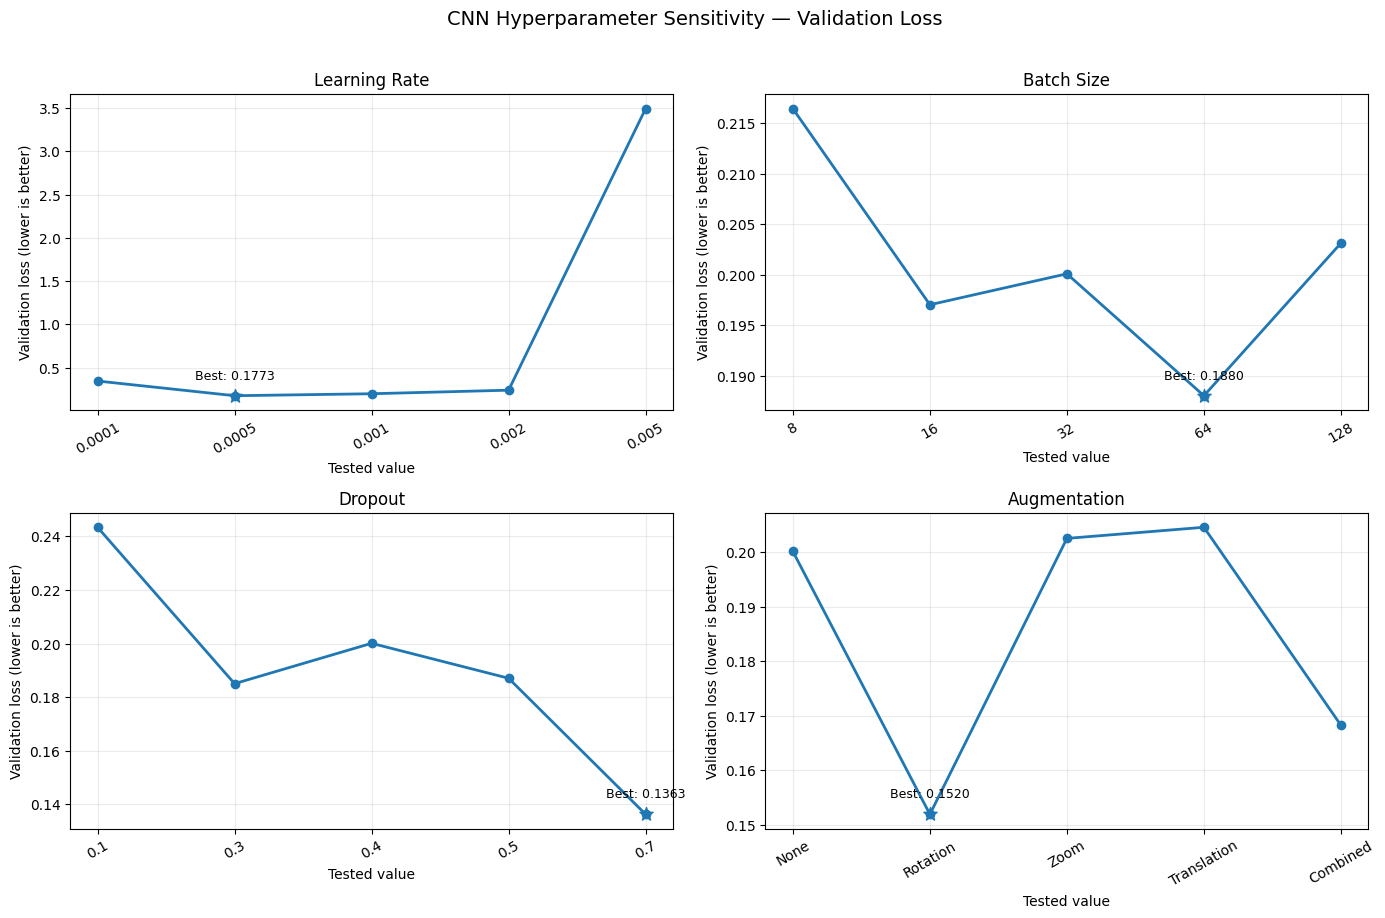

,Experiment,Validation Accuracy,Validation Loss,Training Time (sec)
0,CNN_dropout_V5,0.968062,0.136336,68.974257
1,CNN_AUG_Rotation,0.965136,0.151952,94.698843
2,CNN_Combined_Final,0.961191,0.156711,171.497768
3,CNN_EXP4,0.959919,0.168254,232.894693
4,CNN_learning_rate_V2,0.955211,0.177325,71.700027
5,CNN_EXP3,0.949994,0.185035,47.663369
6,CNN_dropout_V4,0.954574,0.187049,56.422670
7,CNN_EXP2,0.948212,0.187999,54.634942
8,CNN_batch_size_V2,0.959537,0.197013,108.538615
9,CNN_Baseline,0.957246,0.200080,78.056828


In [49]:
# Show sensitivity to each hyperparameter using the recorded validation loss
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (group, group_df) in zip(axes.flat, sensitivity_df.groupby("Group", sort=False)):
    labels = group_df["Tested Value"].astype(str)
    ax.plot(labels, group_df["Validation Loss"], marker="o", linewidth=2)
    best_idx = group_df["Validation Loss"].idxmin()
    best_position = group_df.index.get_loc(best_idx)
    best_loss = group_df.loc[best_idx, "Validation Loss"]
    ax.scatter(best_position, best_loss, s=100, marker="*", zorder=3)
    ax.annotate(f"Best: {best_loss:.4f}", (best_position, best_loss),
                textcoords="offset points", xytext=(0, 12), ha="center", fontsize=9)
    ax.set_title(group)
    ax.set_xlabel("Tested value")
    ax.set_ylabel("Validation loss (lower is better)")
    ax.grid(alpha=0.25)
    ax.tick_params(axis="x", rotation=30)
fig.suptitle("CNN Hyperparameter Sensitivity — Validation Loss", fontsize=14, y=1.015)
plt.tight_layout()
plt.savefig(os.path.join(OPT_RESULTS, "CNN_Sensitivity_Loss.png"), dpi=180, bbox_inches="tight")
plt.show()

# Display the leading recorded experiments
display(all_cnn_results.head(10)[["Experiment", "Validation Accuracy", "Validation Loss", "Training Time (sec)"]])

#### 6.8.1 Main Comparison

The figures compare the baseline, best dropout, rotation augmentation, and combined model using recorded results.

In [50]:
# Calculate evidence-based improvements and export the experiment summary
baseline_row = all_cnn_results.set_index("Experiment").loc["CNN_Baseline"]
winner_row = all_cnn_results.iloc[0]
rotation_row = all_cnn_results.set_index("Experiment").loc["CNN_AUG_Rotation"]
combined_row = all_cnn_results.set_index("Experiment").loc["CNN_Combined_Final"]

summary_table = pd.DataFrame([
    {"Configuration": "Fresh baseline", "Experiment": "CNN_Baseline"},
    {"Configuration": "Best dropout only", "Experiment": "CNN_dropout_V5"},
    {"Configuration": "Rotation only", "Experiment": "CNN_AUG_Rotation"},
    {"Configuration": "Combined settings", "Experiment": "CNN_Combined_Final"},
]).merge(all_cnn_results, on="Experiment", how="left")
summary_table["Accuracy (%)"] = summary_table["Validation Accuracy"] * 100
summary_table["Training Time (min)"] = summary_table["Training Time (sec)"] / 60
summary_table = summary_table[["Configuration", "Experiment", "Accuracy (%)", "Validation Loss", "Training Time (min)", "Parameters"]]
summary_table.to_csv(os.path.join(OPT_RESULTS, "CNN_Key_Results_Comparison.csv"), index=False)
display(summary_table.round(4))

accuracy_gain_pp = (winner_row["Validation Accuracy"] - baseline_row["Validation Accuracy"]) * 100
loss_reduction_pct = (baseline_row["Validation Loss"] - winner_row["Validation Loss"]) / baseline_row["Validation Loss"] * 100
time_reduction_pct = (baseline_row["Training Time (sec)"] - winner_row["Training Time (sec)"]) / baseline_row["Training Time (sec)"] * 100
combined_gap_pp = (winner_row["Validation Accuracy"] - combined_row["Validation Accuracy"]) * 100

print(f"Winner: {winner_row['Experiment']}")
print(f"Accuracy improvement over fresh baseline: +{accuracy_gain_pp:.2f} percentage points")
print(f"Relative validation-loss reduction: {loss_reduction_pct:.2f}%")
print(f"Training-time reduction (observed run): {time_reduction_pct:.2f}%")
print(f"Winner versus combined model: +{combined_gap_pp:.2f} percentage points")
print(f"Parameter count unchanged: {int(winner_row['Parameters']) == int(baseline_row['Parameters'])}")

,Configuration,Experiment,Accuracy (%),Validation Loss,Training Time (min),Parameters
0,Fresh baseline,CNN_Baseline,95.7246,0.2001,1.3009,361067
1,Best dropout only,CNN_dropout_V5,96.8062,0.1363,1.1496,361067
2,Rotation only,CNN_AUG_Rotation,96.5136,0.1520,1.5783,361067
3,Combined settings,CNN_Combined_Final,96.1191,0.1567,2.8583,361067


Winner: CNN_dropout_V5
Accuracy improvement over fresh baseline: +1.08 percentage points
Relative validation-loss reduction: 31.86%
Training-time reduction (observed run): 11.64%
Winner versus combined model: +0.69 percentage points
Parameter count unchanged: True


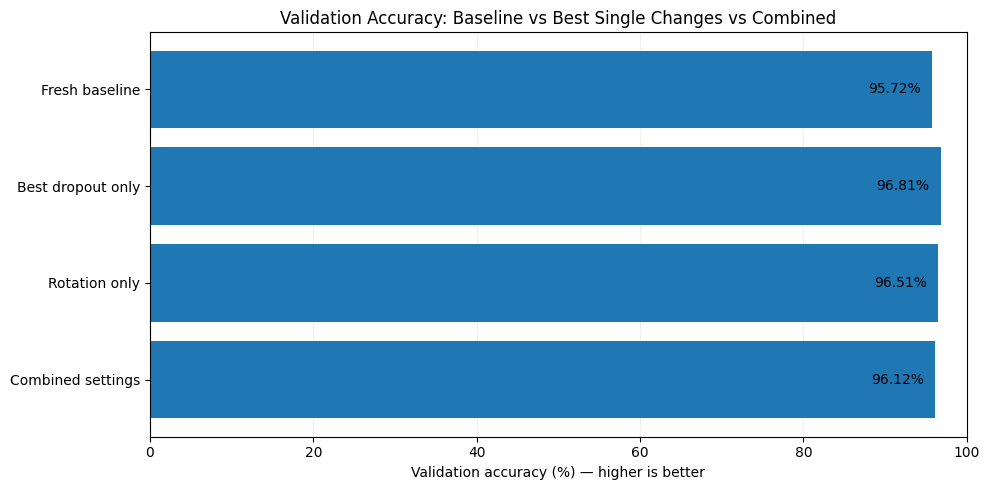

In [51]:
# Compare validation accuracy for the four main configurations
key_names = summary_table["Configuration"].tolist()
key_accuracy = summary_table["Accuracy (%)"].to_numpy()

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(key_names, key_accuracy)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Validation accuracy (%) — higher is better")
ax.set_title("Validation Accuracy: Baseline vs Best Single Changes vs Combined")
ax.grid(axis="x", alpha=0.18)
ax.set_axisbelow(True)
for bar, value in zip(bars, key_accuracy):
    ax.annotate(f"{value:.2f}%", (value, bar.get_y() + bar.get_height() / 2),
                textcoords="offset points", xytext=(-8, 0), ha="right", va="center", fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(OPT_RESULTS, "CNN_Key_Accuracy_Comparison.png"), dpi=180, bbox_inches="tight")
plt.show()

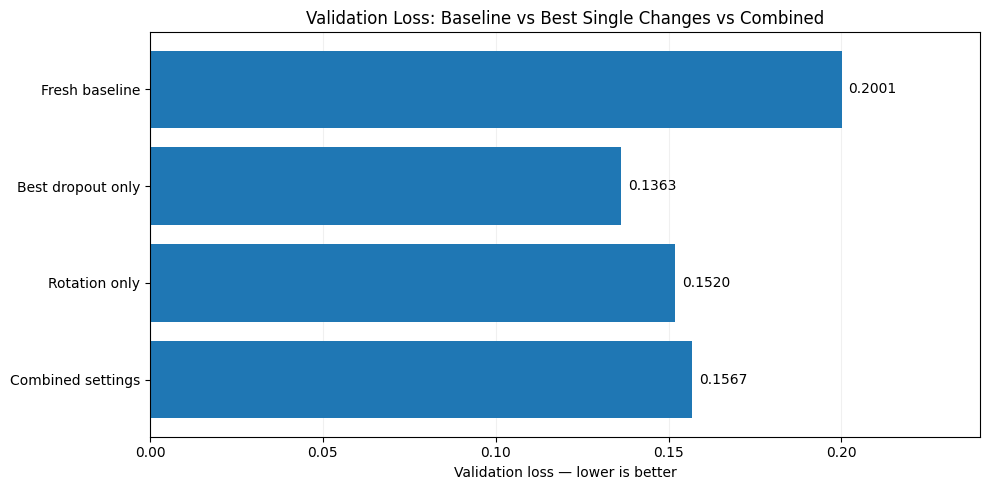

In [52]:
# Compare validation loss for the four main configurations
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(summary_table["Configuration"], summary_table["Validation Loss"])
ax.invert_yaxis()
ax.set_xlabel("Validation loss — lower is better")
ax.set_title("Validation Loss: Baseline vs Best Single Changes vs Combined")
ax.grid(axis="x", alpha=0.18)
ax.set_axisbelow(True)
for bar, value in zip(bars, summary_table["Validation Loss"]):
    ax.annotate(f"{value:.4f}", (value, bar.get_y() + bar.get_height() / 2),
                textcoords="offset points", xytext=(5, 0), ha="left", va="center", fontsize=10)
ax.set_xlim(0, summary_table["Validation Loss"].max() * 1.2)
plt.tight_layout()
plt.savefig(os.path.join(OPT_RESULTS, "CNN_Key_Loss_Comparison.png"), dpi=180, bbox_inches="tight")
plt.show()

#### 6.8.2 Key Findings

- **Baseline:** 95.72% accuracy; validation loss 0.2001.
- **Best individual experiment (dropout 0.7):** 96.81% accuracy; loss 0.1363.
- **Rotation augmentation:** 96.51% accuracy; loss 0.1520.
- **Combined settings:** 96.12% accuracy; loss 0.1567.

Changing dropout from 0.4 to 0.7 improved validation accuracy by **1.08 percentage points** and reduced validation loss by **31.9%** relative to the baseline. The combined configuration did not outperform the dropout-only model.

#### 6.8.3 Hyperparameter Effects

The figure shows validation accuracy across the tested settings. Validation loss is used to select the best values.

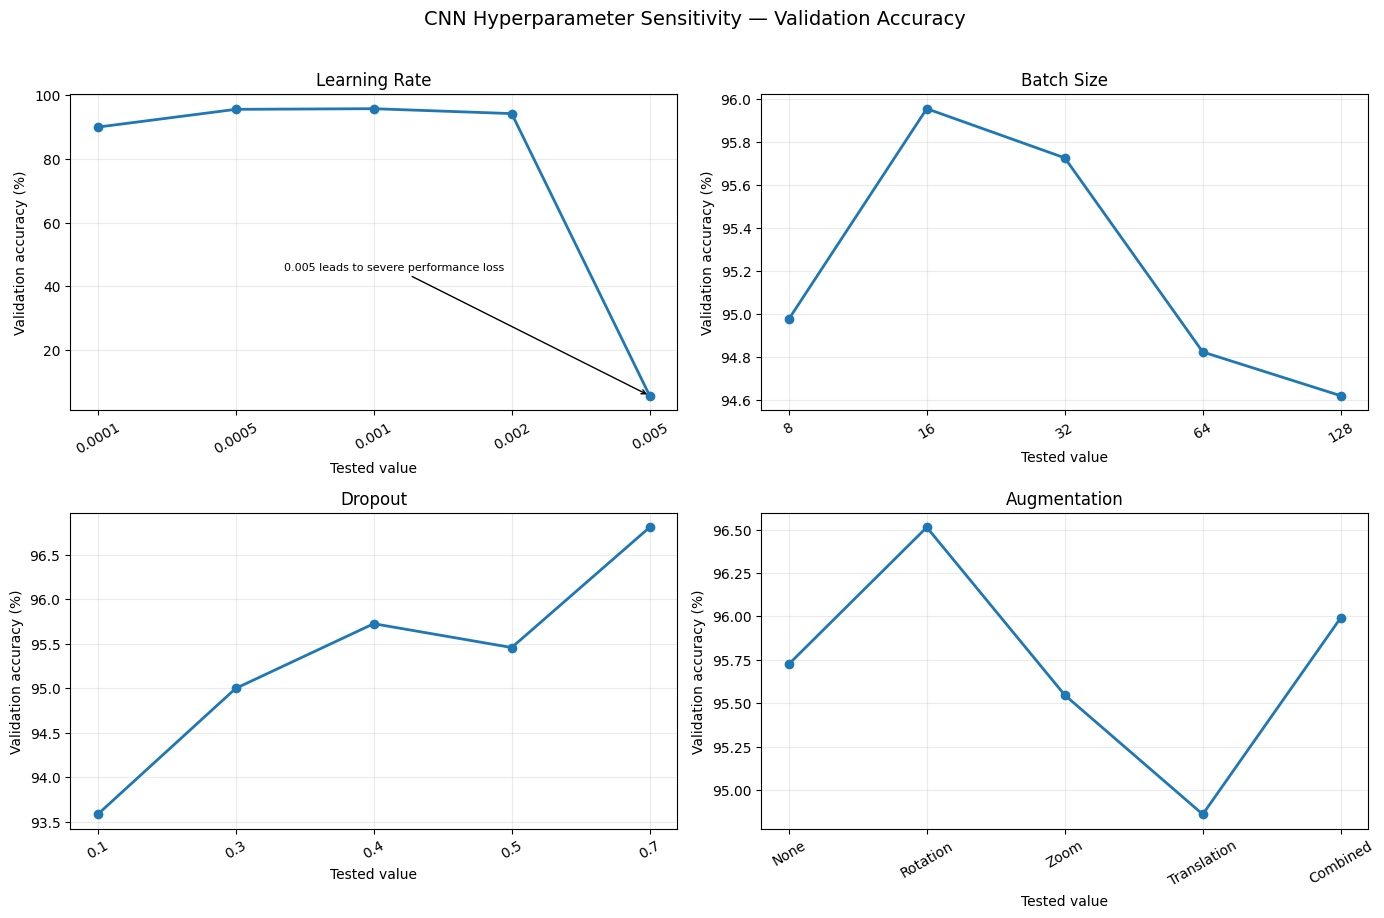

In [53]:
# Plot validation accuracy by tested value for all four sensitivity groups
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (group, group_df) in zip(axes.flat, sensitivity_df.groupby("Group", sort=False)):
    labels = group_df["Tested Value"].astype(str)
    acc = group_df["Validation Accuracy"] * 100
    ax.plot(labels, acc, marker="o", linewidth=2)
    ax.set_title(group)
    ax.set_xlabel("Tested value")
    ax.set_ylabel("Validation accuracy (%)")
    ax.grid(alpha=0.25)
    ax.tick_params(axis="x", rotation=30)
    if group == "Learning Rate":
        ax.annotate("0.005 leads to severe performance loss", xy=(4, acc.iloc[-1]),
                    xytext=(1.35, 45), textcoords="data",
                    arrowprops={"arrowstyle": "->"}, fontsize=8)
fig.suptitle("CNN Hyperparameter Sensitivity — Validation Accuracy", fontsize=14, y=1.015)
plt.tight_layout()
plt.savefig(os.path.join(OPT_RESULTS, "CNN_Sensitivity_Accuracy.png"), dpi=180, bbox_inches="tight")
plt.show()

#### 6.8.4 Parameter Summary

| Parameter | Best value by validation loss | Observation |
|---|---|---|
| Learning rate | 0.0005 | A larger learning rate (0.005) performed poorly. |
| Batch size | 64 | Lowest loss differed from the highest-accuracy batch size. |
| Dropout | 0.7 | Best overall CNN result in these experiments. |
| Augmentation | Rotation | Better than the combined augmentation policy. |

### 6.9 Final CNN Model

Select and export the checkpoint with the lowest validation loss. The test set is not used for selection.

In [54]:
# Select and export the best saved CNN model
import shutil

winner = all_cnn_results.loc[all_cnn_results["Validation Loss"].idxmin()]
winner_name = str(winner["Experiment"])
source_model = os.path.join(OPT_MODELS, f"{winner_name}.keras")
final_model = os.path.join(MODELS_DIR, "model1_final.keras")

if not os.path.isfile(source_model):
    raise FileNotFoundError(f"Selected model is missing: {source_model}")
shutil.copy2(source_model, final_model)

final_summary = pd.DataFrame([winner])
final_summary.to_csv(os.path.join(OPT_RESULTS, "CNN_Final_Model_Summary.csv"), index=False)
print("Selected model:", winner_name)
print("Validation accuracy:", f"{winner['Validation Accuracy']:.4%}")
print("Validation loss:", f"{winner['Validation Loss']:.4f}")
print("Training time (min):", f"{winner['Training Time (sec)']/60:.2f}")
print("Parameters:", int(winner["Parameters"]))
print("Saved final model:", final_model)

# Export validation predictions and probabilities for team integration
final_cnn = tf.keras.models.load_model(final_model)
val_probabilities = final_cnn.predict(X_val, batch_size=64, verbose=0)
val_predictions = val_probabilities.argmax(axis=1)
pd.DataFrame({"ClassId": y_val, "Prediction": val_predictions}).to_csv(
    os.path.join(OPT_RESULTS, "CNN_Final_Validation_Predictions.csv"), index=False
)
np.save(os.path.join(OPT_RESULTS, "CNN_Final_Validation_Probabilities.npy"), val_probabilities)
print("Validation predictions and probabilities exported.")

Selected model: CNN_dropout_V5
Validation accuracy: 96.8062%
Validation loss: 0.1363
Training time (min): 1.15
Parameters: 361067
Saved final model: /content/drive/MyDrive/ARTI502_Project/models/model1_final.keras
Validation predictions and probabilities exported.


### 6.10 CNN Validation Evaluation

Evaluate the saved best checkpoint with per-class metrics, confusion matrix, and real misclassified traffic sign images.

#### 6.10.1 Saved Checkpoint Verification

In [55]:
# Re-evaluate the exact exported model and verify its recorded validation metrics
saved_val_loss, saved_val_accuracy = final_cnn.evaluate(X_val, y_val, batch_size=64, verbose=0)
recorded_loss = float(winner["Validation Loss"])
recorded_accuracy = float(winner["Validation Accuracy"])
print(f"Saved model validation accuracy: {saved_val_accuracy:.4%}")
print(f"Recorded model validation accuracy: {recorded_accuracy:.4%}")
print(f"Saved model validation loss: {saved_val_loss:.6f}")
print(f"Recorded model validation loss: {recorded_loss:.6f}")
print("Parameter count:", final_cnn.count_params())

if abs(saved_val_loss - recorded_loss) > 1e-3 or abs(saved_val_accuracy - recorded_accuracy) > 1e-4:
    print("WARNING: Saved checkpoint metrics differ from recorded results. Inspect model/data consistency.")
else:
    print("Checkpoint verification passed on validation data.")


Saved model validation accuracy: 96.8062%
Recorded model validation accuracy: 96.8062%
Saved model validation loss: 0.136336
Recorded model validation loss: 0.136336
Parameter count: 361067
Checkpoint verification passed on validation data.


#### 6.10.2 Per-Class Precision, Recall & F1

In [56]:
# Calculate per-class validation precision, recall, and F1-score
from sklearn.metrics import precision_recall_fscore_support

class_ids = sorted(int(x) for x in val_df["ClassId"].unique())
class_name_lookup = (val_df[["ClassId", "ClassName"]]
                     .drop_duplicates("ClassId")
                     .set_index("ClassId")["ClassName"].to_dict())
class_names = [class_name_lookup[i] for i in class_ids]
assert len(class_ids) == 43, "Expected 43 GTSRB traffic-sign classes."
assert len(val_predictions) == len(y_val) == len(val_df)

precision, recall, f1, support = precision_recall_fscore_support(
    y_val, val_predictions, labels=class_ids, zero_division=0
)
class_metrics = pd.DataFrame({
    "ClassId": class_ids,
    "ClassName": class_names,
    "Support": support,
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1,
    "Errors": support - np.rint(recall * support).astype(int)
})
class_metrics = class_metrics.sort_values(["F1-score", "Support"], ascending=[True, False])
class_metrics.to_csv(os.path.join(OPT_RESULTS, "CNN_Validation_Per_Class_Metrics.csv"), index=False)

macro_f1 = f1_score(y_val, val_predictions, average="macro", zero_division=0)
weighted_f1 = f1_score(y_val, val_predictions, average="weighted", zero_division=0)
model_accuracy = accuracy_score(y_val, val_predictions)
error_count = int(np.sum(np.asarray(val_predictions) != np.asarray(y_val)))

val_metrics_summary = pd.DataFrame([{
    "Selected Model": winner_name,
    "Validation Accuracy": model_accuracy,
    "Validation Loss": saved_val_loss,
    "Macro F1": macro_f1,
    "Weighted F1": weighted_f1,
    "Validation Samples": len(y_val),
    "Incorrect Predictions": error_count,
    "Classes": len(class_ids)
}])
val_metrics_summary.to_csv(os.path.join(OPT_RESULTS, "CNN_Validation_Detailed_Summary.csv"), index=False)
report_text = classification_report(y_val, val_predictions, labels=class_ids,
                                    target_names=class_names, zero_division=0)
with open(os.path.join(OPT_RESULTS, "CNN_Validation_Classification_Report.txt"), "w", encoding="utf-8") as f:
    f.write(report_text)

print("Overall validation summary:")
display(val_metrics_summary.round(4))
print("Five lowest-F1 classes (on this validation split):")
display(class_metrics.head(5).round(4))
print("Five highest-error-count classes:")
display(class_metrics.sort_values("Errors", ascending=False).head(5).round(4))
print("Per-class CSV and classification report saved to Drive.")

Overall validation summary:


,Selected Model,Validation Accuracy,Validation Loss,Macro F1,Weighted F1,Validation Samples,Incorrect Predictions,Classes
0,CNN_dropout_V5,0.9681,0.1363,0.9524,0.9677,7859,251,43


Five lowest-F1 classes (on this validation split):


,ClassId,ClassName,Support,Precision,Recall,F1-score,Errors
19,19,Dangerous curve left,30,0.7353,0.8333,0.7812,5
26,26,Traffic signals,120,1.0000,0.6750,0.8060,39
32,32,End speed + passing limits,60,1.0000,0.7167,0.8350,17
40,40,Roundabout mandatory,60,0.7500,1.0000,0.8571,0
39,39,Keep left,60,1.0000,0.7667,0.8679,14


Five highest-error-count classes:


,ClassId,ClassName,Support,Precision,Recall,F1-score,Errors
26,26,Traffic signals,120,1.0000,0.6750,0.8060,39
3,3,Speed limit (60km/h),270,0.9675,0.8815,0.9225,32
5,5,Speed limit (80km/h),360,0.8989,0.9389,0.9185,22
38,38,Keep right,420,0.9780,0.9524,0.9650,20
32,32,End speed + passing limits,60,1.0000,0.7167,0.8350,17


Per-class CSV and classification report saved to Drive.


#### 6.10.3 Confusion Matrix (Real Validation Predictions)

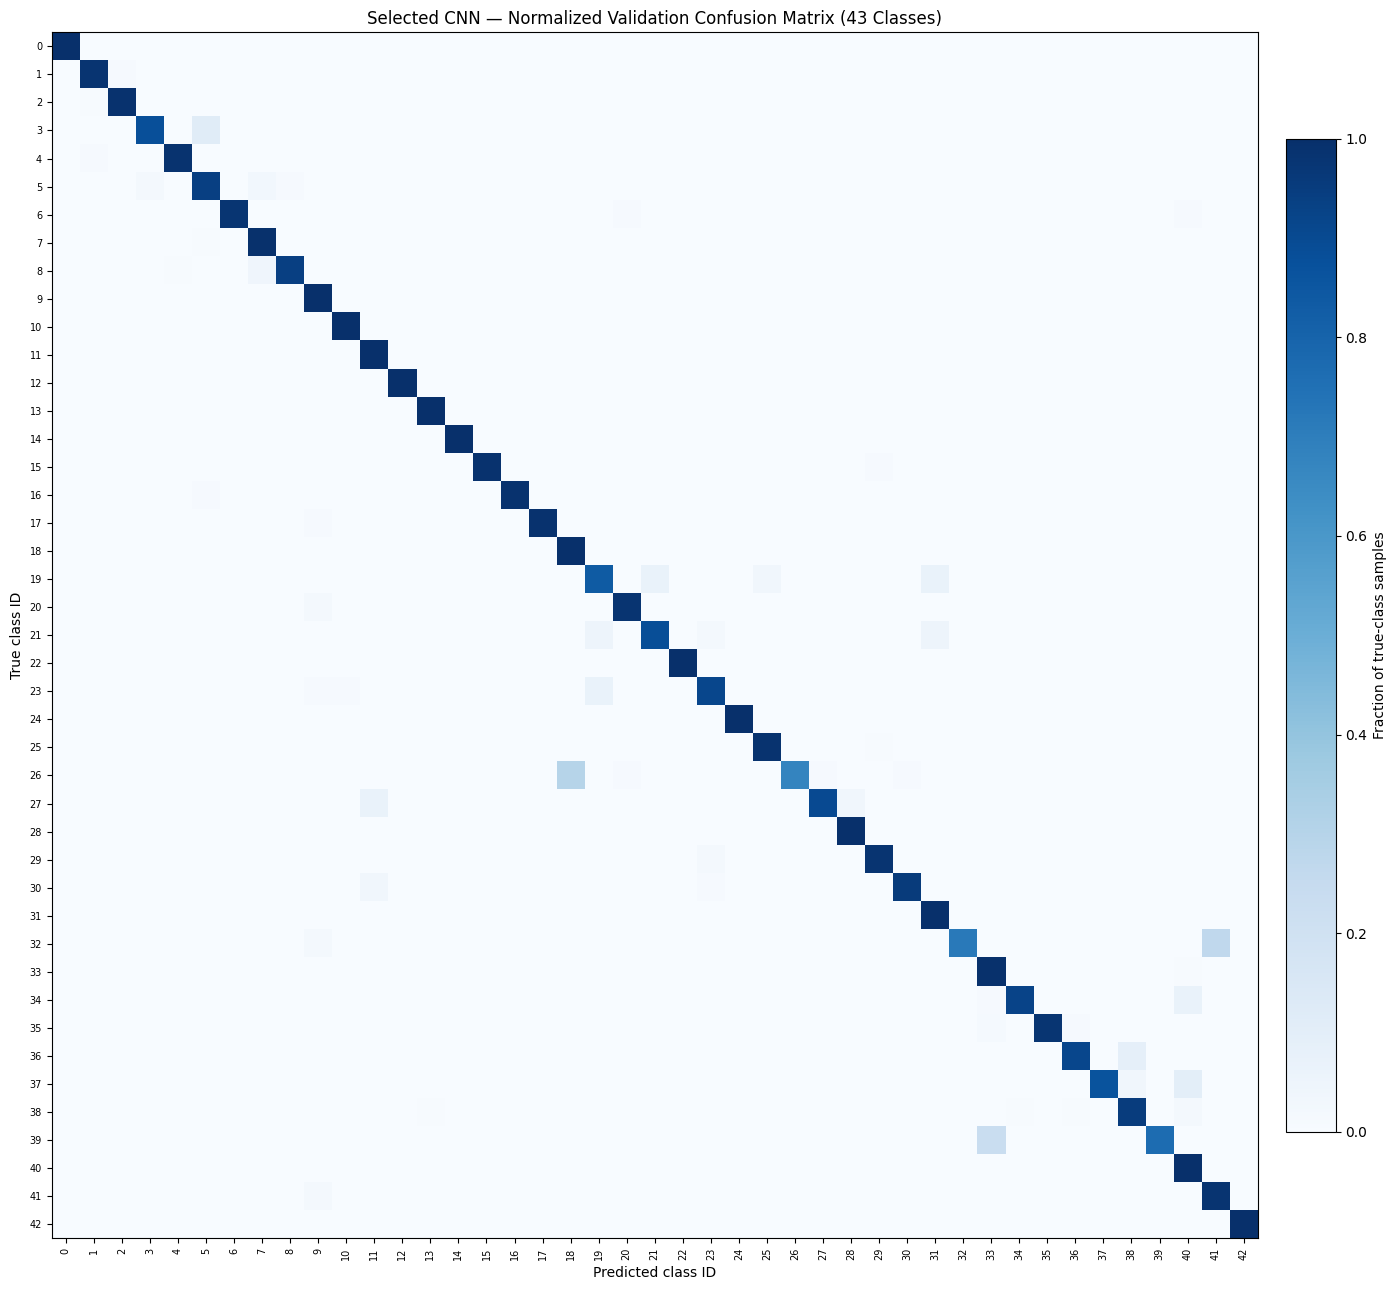

Use CNN_Validation_Per_Class_Metrics.csv to map class IDs to full class names.


In [57]:
# Visualize the row-normalized confusion matrix of the 43 GTSRB classes
cm = confusion_matrix(y_val, val_predictions, labels=class_ids)
cm_normalized = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
pd.DataFrame(cm, index=class_ids, columns=class_ids).to_csv(
    os.path.join(OPT_RESULTS, "CNN_Validation_Confusion_Matrix_Counts.csv")
)

fig, ax = plt.subplots(figsize=(15, 13))
im = ax.imshow(cm_normalized, interpolation="nearest", cmap="Blues", vmin=0, vmax=1)
fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02, label="Fraction of true-class samples")
ax.set_xticks(np.arange(len(class_ids)))
ax.set_yticks(np.arange(len(class_ids)))
ax.set_xticklabels(class_ids, rotation=90, fontsize=7)
ax.set_yticklabels(class_ids, fontsize=7)
ax.set_xlabel("Predicted class ID")
ax.set_ylabel("True class ID")
ax.set_title("Selected CNN — Normalized Validation Confusion Matrix (43 Classes)")
plt.tight_layout()
plt.savefig(os.path.join(OPT_RESULTS, "CNN_Validation_Confusion_Matrix.png"), dpi=200, bbox_inches="tight")
plt.show()
print("Use CNN_Validation_Per_Class_Metrics.csv to map class IDs to full class names.")

#### 6.10.4 Frequent Confusion Pairs

,True ClassId,True ClassName,Predicted ClassId,Predicted ClassName,Count
43,26,Traffic signals,18,General caution,36
7,3,Speed limit (60km/h),5,Speed limit (80km/h),31
53,32,End speed + passing limits,41,End of no passing,16
69,39,Keep left,33,Turn right ahead,14
23,8,Speed limit (120km/h),7,Speed limit (100km/h),11
14,5,Speed limit (80km/h),7,Speed limit (100km/h),10
68,38,Keep right,40,Roundabout mandatory,9
59,36,Go straight or right,38,Keep right,8
13,5,Speed limit (80km/h),3,Speed limit (60km/h),7
39,23,Slippery road,19,Dangerous curve left,6


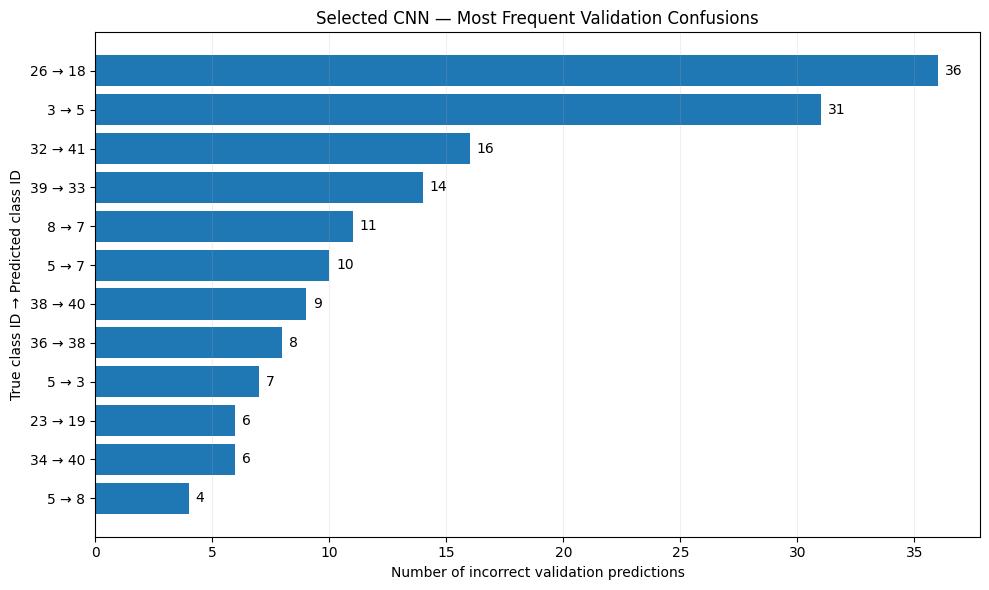

In [58]:
# Identify the most frequent wrong class-to-class predictions
error_pairs = []
for true_pos, true_id in enumerate(class_ids):
    for pred_pos, predicted_id in enumerate(class_ids):
        count = int(cm[true_pos, pred_pos])
        if count and true_pos != pred_pos:
            error_pairs.append({
                "True ClassId": true_id,
                "True ClassName": class_name_lookup[true_id],
                "Predicted ClassId": predicted_id,
                "Predicted ClassName": class_name_lookup[predicted_id],
                "Count": count
            })
error_pairs_df = pd.DataFrame(error_pairs).sort_values("Count", ascending=False)
error_pairs_df.to_csv(os.path.join(OPT_RESULTS, "CNN_Validation_Most_Confused_Pairs.csv"), index=False)
display(error_pairs_df.head(12))

if len(error_pairs_df):
    top_pairs = error_pairs_df.head(12).iloc[::-1]
    pair_labels = [f"{int(r['True ClassId'])} → {int(r['Predicted ClassId'])}" for _, r in top_pairs.iterrows()]
    fig, ax = plt.subplots(figsize=(10, 6))
    bars = ax.barh(pair_labels, top_pairs["Count"])
    ax.set_xlabel("Number of incorrect validation predictions")
    ax.set_ylabel("True class ID → Predicted class ID")
    ax.set_title("Selected CNN — Most Frequent Validation Confusions")
    ax.grid(axis="x", alpha=0.2)
    for bar, count in zip(bars, top_pairs["Count"]):
        ax.annotate(str(int(count)), (bar.get_width(), bar.get_y() + bar.get_height() / 2),
                    xytext=(5, 0), textcoords="offset points", va="center")
    plt.tight_layout()
    plt.savefig(os.path.join(OPT_RESULTS, "CNN_Validation_Top_Confusions.png"), dpi=180, bbox_inches="tight")
    plt.show()
else:
    print("No validation misclassifications to visualize.")

#### 6.10.5 Image Gallery — Actual Misclassified Signs

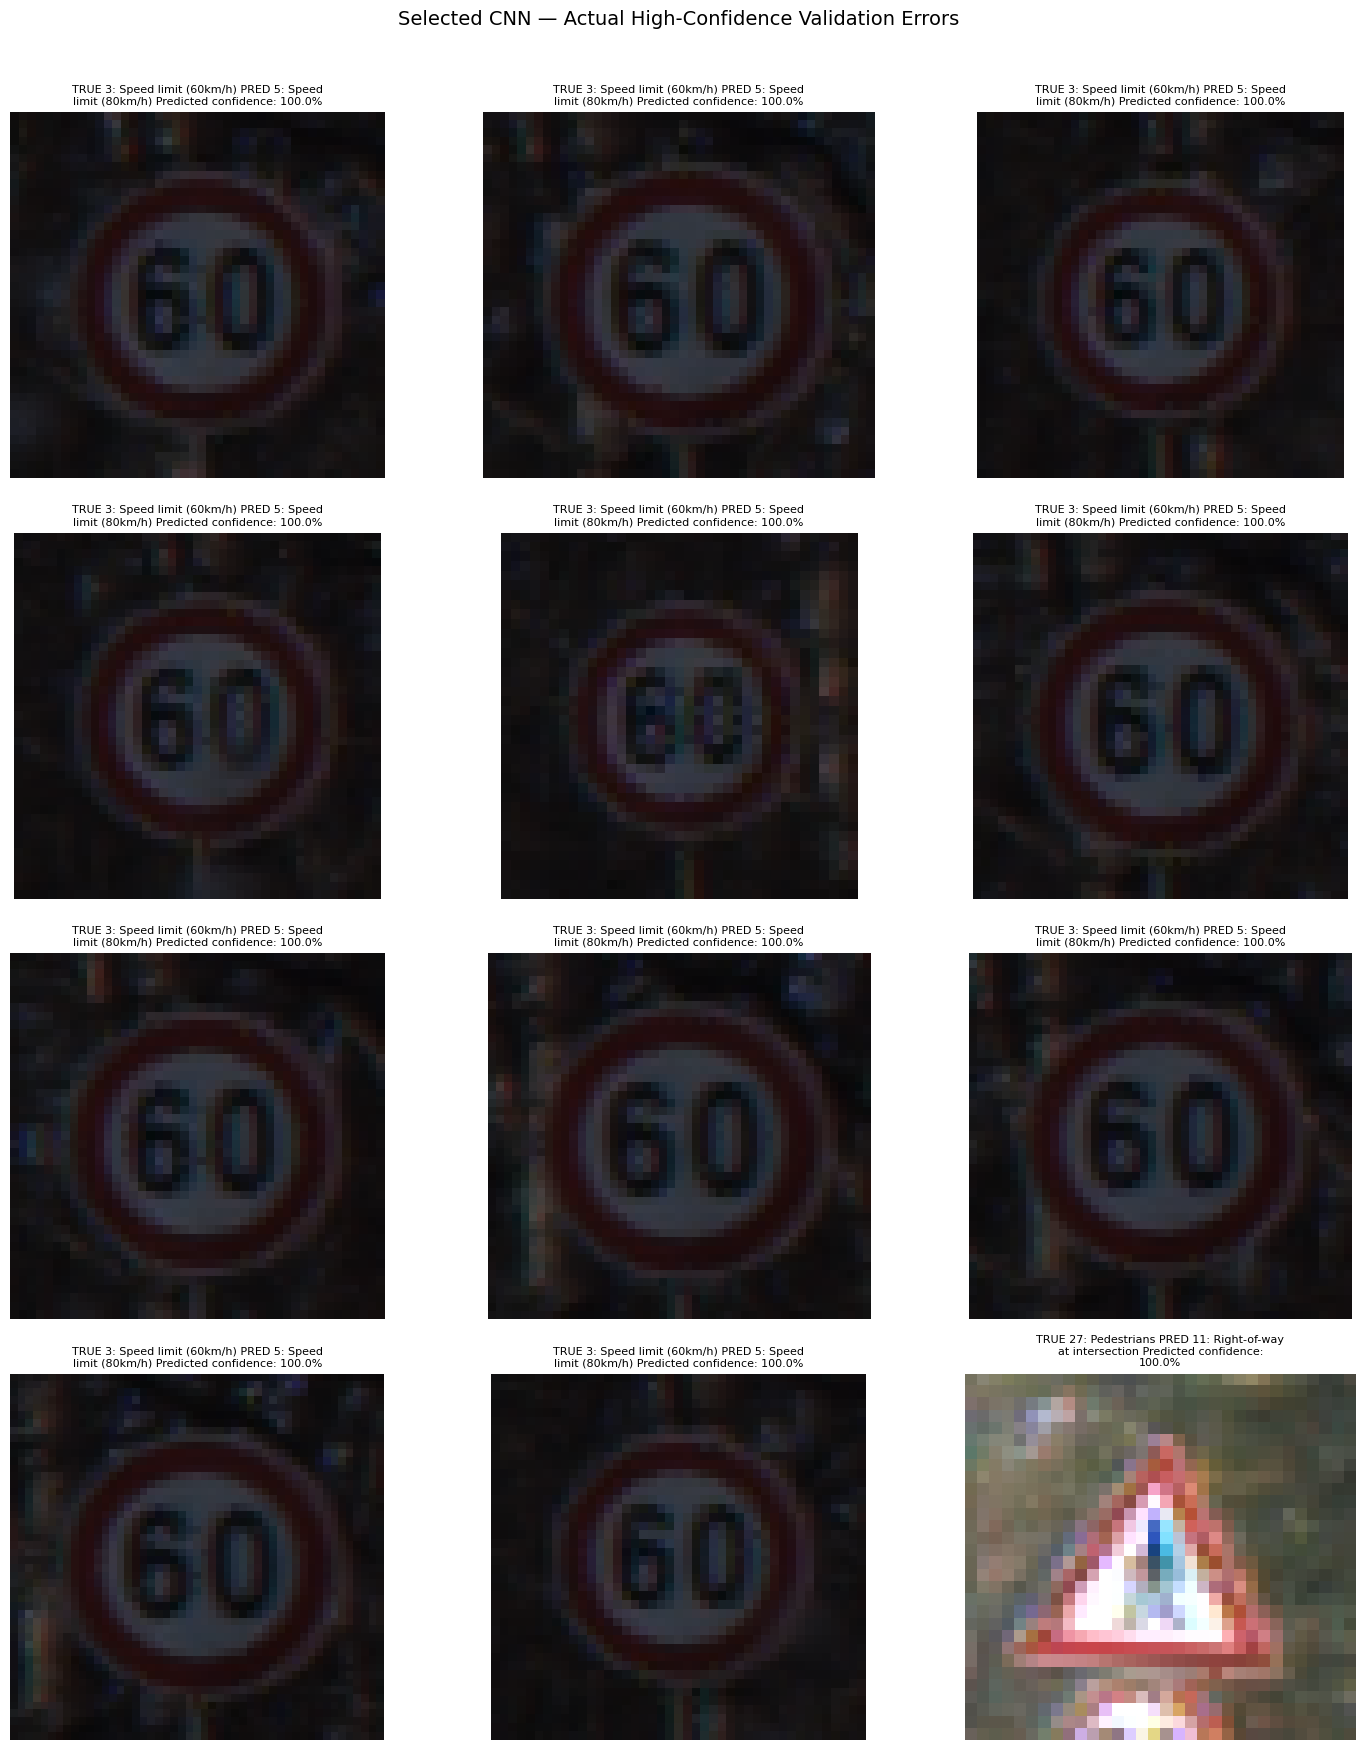

In [59]:
# Plot real validation samples where the selected CNN made incorrect predictions
import textwrap

wrong_indices = np.flatnonzero(np.asarray(val_predictions) != np.asarray(y_val))
wrong_confidences = val_probabilities[wrong_indices].max(axis=1)
wrong_indices = wrong_indices[np.argsort(wrong_confidences)[::-1]]
shown_indices = wrong_indices[:12]

error_examples = pd.DataFrame({
    "Validation Row": wrong_indices,
    "Image Path": val_df.iloc[wrong_indices]["Path"].to_numpy(),
    "True ClassId": np.asarray(y_val)[wrong_indices],
    "Predicted ClassId": np.asarray(val_predictions)[wrong_indices],
    "Predicted Confidence": np.asarray(val_probabilities)[wrong_indices].max(axis=1)
})
error_examples["True ClassName"] = error_examples["True ClassId"].map(class_name_lookup)
error_examples["Predicted ClassName"] = error_examples["Predicted ClassId"].map(class_name_lookup)
error_examples.to_csv(os.path.join(OPT_RESULTS, "CNN_Validation_Error_Examples.csv"), index=False)

if len(shown_indices):
    columns = 3
    rows = int(np.ceil(len(shown_indices) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(15, rows * 4.3))
    axes = np.asarray(axes).reshape(-1)
    for ax, i in zip(axes, shown_indices):
        row = val_df.iloc[int(i)]
        with Image.open(DATASET_ROOT / row["Path"]) as img:
            image = img.convert("RGB").copy()
        true_id = int(y_val[i])
        predicted_id = int(val_predictions[i])
        confidence = float(val_probabilities[i, predicted_id])
        ax.imshow(image)
        title = (f"TRUE {true_id}: {class_name_lookup[true_id]}\n"
                 f"PRED {predicted_id}: {class_name_lookup[predicted_id]}\n"
                 f"Predicted confidence: {confidence:.1%}")
        ax.set_title("\n".join(textwrap.wrap(title, width=43, break_long_words=False)), fontsize=8)
        ax.axis("off")
    for ax in axes[len(shown_indices):]:
        ax.axis("off")
    fig.suptitle("Selected CNN — Actual High-Confidence Validation Errors", fontsize=14, y=1.015)
    plt.tight_layout()
    plt.savefig(os.path.join(OPT_RESULTS, "CNN_Validation_Misclassified_Examples.png"), dpi=180, bbox_inches="tight")
    plt.show()
else:
    print("No validation prediction errors were found.")


In [60]:
# Write an evidence-based diagnostic summary using measured class-level errors
hardest = class_metrics.iloc[0]
most_errors = class_metrics.sort_values("Errors", ascending=False).iloc[0]
print("Detailed validation interpretation")
print("----------------------------------")
print(f"Overall correct: {int(len(y_val) - error_count):,} / {len(y_val):,}")
print(f"Overall errors: {error_count:,} ({error_count / len(y_val):.2%})")
print(f"Macro F1: {macro_f1:.4f}; weighted F1: {weighted_f1:.4f}")
print(f"Lowest F1 class: {int(hardest['ClassId'])} — {hardest['ClassName']} (F1={hardest['F1-score']:.3f}, n={int(hardest['Support'])})")
print(f"Most errors by true class: {int(most_errors['ClassId'])} — {most_errors['ClassName']} ({int(most_errors['Errors'])} mistakes)")
if len(error_pairs_df):
    pair = error_pairs_df.iloc[0]
    print(f"Most common confusion: {int(pair['True ClassId'])} → {int(pair['Predicted ClassId'])} ({int(pair['Count'])} errors)")
print("Interpretation: per-class variation can be checked in the confusion matrix, CSV report, and actual error examples.")
print("This analysis describes validation performance only; test evaluation is still pending.")

Detailed validation interpretation
----------------------------------
Overall correct: 7,608 / 7,859
Overall errors: 251 (3.19%)
Macro F1: 0.9524; weighted F1: 0.9677
Lowest F1 class: 19 — Dangerous curve left (F1=0.781, n=30)
Most errors by true class: 26 — Traffic signals (39 mistakes)
Most common confusion: 26 → 18 (36 errors)
Interpretation: per-class variation can be checked in the confusion matrix, CSV report, and actual error examples.
This analysis describes validation performance only; test evaluation is still pending.


**Reading the figures:** The confusion matrix shows which classes are confused; the image gallery shows real validation mistakes with true and predicted labels. These results describe validation performance, not final test performance.

## 7. Model 2 — YOLOv8n-cls Optimization

Use the same data splits and report baseline, tuning, results, and validation examples.

### 7.1 Setup

In [61]:
%pip -q install "ultralytics>=8.4,<9" kagglehub scikit-learn pillow

In [62]:
# Import only the packages needed for YOLO experiments
import os
import json
import random
import shutil
import time
import gc
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image
from IPython.display import display, Markdown
from sklearn.metrics import (
    accuracy_score, f1_score, precision_recall_fscore_support,
    classification_report, confusion_matrix, log_loss
)
from google.colab import drive
import kagglehub
import ultralytics
from ultralytics import YOLO

SEED = 42
NUM_CLASSES = 43
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("Seed:", SEED)

Ultralytics: 8.4.216
PyTorch: 2.14.1+cpu
GPU: CPU
Seed: 42


### 7.2 Data Splits

Use the same training and validation CSV files as the CNN.

In [63]:
# Connect the same Drive root used in the CNN optimization notebook
drive.mount("/content/drive")
PROJECT_ROOT = Path("/content/drive/MyDrive/ARTI502_Project")
YOLO_DATA_DIR = PROJECT_ROOT / "data"
YOLO_MODELS_DIR = PROJECT_ROOT / "models"
YOLO_RESULTS_DIR = PROJECT_ROOT / "results"
YOLO_OPT_MODELS = YOLO_MODELS_DIR / "optimization"
YOLO_OPT_RESULTS = YOLO_RESULTS_DIR / "optimization"
YOLO_RUNS_DIR = YOLO_OPT_RESULTS / "yolo_training_runs"
for folder in (YOLO_OPT_MODELS, YOLO_OPT_RESULTS, YOLO_RUNS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

YOLO_ORIGINAL_MODEL = YOLO_MODELS_DIR / "model2.pt"
for required in [YOLO_DATA_DIR / "train_split.csv", YOLO_DATA_DIR / "val_split.csv", YOLO_ORIGINAL_MODEL]:
    if not required.is_file():
        raise FileNotFoundError(f"Required shared project file is missing: {required}")

yolo_train_df = pd.read_csv(YOLO_DATA_DIR / "train_split.csv")
yolo_val_df = pd.read_csv(YOLO_DATA_DIR / "val_split.csv")
YOLO_TEST_CSV = YOLO_DATA_DIR / "test_split.csv"
yolo_test_count = len(pd.read_csv(YOLO_TEST_CSV)) if YOLO_TEST_CSV.exists() else None

for split_name, frame, expected in [("Train", yolo_train_df, 31350), ("Validation", yolo_val_df, 7859)]:
    assert {"Path", "ClassId"}.issubset(frame.columns), f"Missing required columns in {split_name} CSV"
    assert len(frame) == expected, f"Unexpected {split_name} set size: {len(frame)}"
    assert frame["ClassId"].nunique() == NUM_CLASSES, f"Expected 43 classes in {split_name}"
    assert frame["Path"].notna().all(), f"Missing paths in {split_name}"

assert set(yolo_train_df["Path"]).isdisjoint(set(yolo_val_df["Path"])), "Split path leakage detected"

# Verify the track-based split if the original GTSRB naming pattern is present
track_pattern = r"/(\d+_\d+)_\d+\.png$"
train_tracks = yolo_train_df["Path"].str.extract(track_pattern, expand=False)
val_tracks = yolo_val_df["Path"].str.extract(track_pattern, expand=False)
if train_tracks.notna().all() and val_tracks.notna().all():
    assert set(train_tracks).isdisjoint(set(val_tracks)), "Track leakage detected between train and val"

print("Train images:", len(yolo_train_df))
print("Validation images:", len(yolo_val_df))
print("Official test images (excluded from optimization):", yolo_test_count)
print("Saved original checkpoint:", YOLO_ORIGINAL_MODEL)
print("Optimization checkpoints:", YOLO_OPT_MODELS)
print("Optimization metrics:", YOLO_OPT_RESULTS)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Train images: 31350
Validation images: 7859
Official test images (excluded from optimization): 12630
Saved original checkpoint: /content/drive/MyDrive/ARTI502_Project/models/model2.pt
Optimization checkpoints: /content/drive/MyDrive/ARTI502_Project/models/optimization
Optimization metrics: /content/drive/MyDrive/ARTI502_Project/results/optimization


### 7.3 Prepare YOLO Data

Arrange the 43 classes into training and validation folders. Keep image flips disabled for traffic signs.

In [64]:
# Download original image bytes if they are not in the current Colab cache
YOLO_IMAGE_ROOT = Path(kagglehub.dataset_download("meowmeowmeowmeowmeow/gtsrb-german-traffic-sign"))
YOLO_LOCAL_DATA = Path("/content/yolo_gtsrb_classification")

assert (YOLO_IMAGE_ROOT / str(yolo_train_df.iloc[0]["Path"])).is_file(), "Cannot resolve GTSRB training image"
assert (YOLO_IMAGE_ROOT / str(yolo_val_df.iloc[0]["Path"])).is_file(), "Cannot resolve GTSRB validation image"

def build_yolo_classification_split(frame, split_name):
    for class_id in range(NUM_CLASSES):
        (YOLO_LOCAL_DATA / split_name / f"{class_id:02d}").mkdir(parents=True, exist_ok=True)
    for row in frame.itertuples(index=False):
        original = YOLO_IMAGE_ROOT / str(row.Path)
        target = YOLO_LOCAL_DATA / split_name / f"{int(row.ClassId):02d}" / Path(row.Path).name
        if not original.is_file():
            raise FileNotFoundError(f"Missing dataset image: {original}")
        if target.is_symlink() and not target.exists():
            target.unlink()
        if not target.exists():
            try:
                os.symlink(str(original), str(target))
            except OSError:
                shutil.copy2(original, target)

def linked_image_count(split_name):
    return sum(1 for path in (YOLO_LOCAL_DATA / split_name).rglob("*.png") if path.is_file())

# Repair or create local links without deleting existing valid directories
for split_name, frame in [("train", yolo_train_df), ("val", yolo_val_df)]:
    if linked_image_count(split_name) != len(frame):
        build_yolo_classification_split(frame, split_name)
    actual = linked_image_count(split_name)
    assert actual == len(frame), f"Invalid {split_name} link count: {actual}"
    print(f"YOLO {split_name}: {actual:,} images")

print("Image root:", YOLO_IMAGE_ROOT)
print("YOLO training data:", YOLO_LOCAL_DATA)

Using Colab cache for faster access to the 'gtsrb-german-traffic-sign' dataset.
YOLO train: 31,350 images
YOLO val: 7,859 images
Image root: /kaggle/input/gtsrb-german-traffic-sign
YOLO training data: /content/yolo_gtsrb_classification


### 7.4 Original Model & Baseline

The original saved YOLOv8n-cls checkpoint recorded **98.85% validation accuracy** and **0.9882 macro F1**. Evaluate it on the shared validation split and train a fresh baseline using the same setup before tuning.

In [65]:
# Map output indices to the original numeric class IDs (00 through 42)
def yolo_class_order(yolo_model):
    raw_names = yolo_model.names
    names = [raw_names[i] if isinstance(raw_names, dict) else raw_names[i] for i in range(NUM_CLASSES)]
    try:
        order = [int(name) for name in names]
    except (ValueError, TypeError) as error:
        raise ValueError(f"Unexpected checkpoint class names: {names}") from error
    assert sorted(order) == list(range(NUM_CLASSES)), "Checkpoint class mapping is not a permutation of IDs 0–42"
    return order

def yolo_predict_probabilities(model_path, frame, imgsz=128, image_batch_size=64):
    trained_model = YOLO(str(model_path))
    class_order = yolo_class_order(trained_model)
    predictions = np.zeros((len(frame), NUM_CLASSES), dtype=np.float32)
    all_paths = [str(YOLO_IMAGE_ROOT / str(path)) for path in frame["Path"]]
    for start in range(0, len(frame), image_batch_size):
        current_paths = all_paths[start:start + image_batch_size]
        outputs = trained_model.predict(
            source=current_paths, imgsz=imgsz, batch=image_batch_size,
            device=0 if torch.cuda.is_available() else "cpu",
            verbose=False, save=False
        )
        assert len(outputs) == len(current_paths), "Prediction batch length mismatch"
        for offset, output in enumerate(outputs):
            predictions[start + offset, class_order] = output.probs.data.cpu().numpy()
    row_sums = predictions.sum(axis=1)
    assert np.allclose(row_sums, 1, atol=5e-4), "Prediction probabilities are not normalized"
    return predictions

def yolo_evaluate_predictions(probabilities, true_labels):
    predicted = probabilities.argmax(axis=1)
    return {
        "Validation Accuracy": float(accuracy_score(true_labels, predicted)),
        "Validation Loss": float(log_loss(true_labels, probabilities, labels=list(range(NUM_CLASSES)))),
        "Macro F1": float(f1_score(true_labels, predicted, average="macro", zero_division=0)),
    }

YOLO_LABELS_VAL = yolo_val_df["ClassId"].to_numpy(dtype=int)
ORIGINAL_RESULT_FILE = YOLO_OPT_RESULTS / "YOLO_Original_Reference_results.csv"
ORIGINAL_PROBS_FILE = YOLO_OPT_RESULTS / "YOLO_Original_Reference_val_probs.npy"
ORIGINAL_PRED_FILE = YOLO_OPT_RESULTS / "YOLO_Original_Reference_val_predictions.csv"

original_yolo = YOLO(str(YOLO_ORIGINAL_MODEL))
original_parameters = int(sum(parameter.numel() for parameter in original_yolo.model.parameters()))
if ORIGINAL_RESULT_FILE.is_file() and ORIGINAL_PROBS_FILE.is_file() and ORIGINAL_PRED_FILE.is_file():
    original_reference = pd.read_csv(ORIGINAL_RESULT_FILE).iloc[0].to_dict()
    original_yolo_probs = np.load(ORIGINAL_PROBS_FILE)
    assert original_yolo_probs.shape == (len(yolo_val_df), NUM_CLASSES)
    print("Reused the saved original YOLO validation results")
else:
    original_yolo_probs = yolo_predict_probabilities(YOLO_ORIGINAL_MODEL, yolo_val_df)
    reference_metrics = yolo_evaluate_predictions(original_yolo_probs, YOLO_LABELS_VAL)
    original_reference = {
        "Experiment": "YOLO_Original_Reference", **reference_metrics,
        "Training Time (sec)": 13.4 * 60,
        "Training Time Provenance": "Original model notebook; approximate historical timing",
        "Parameters": original_parameters,
        "Learning Rate": 0.001, "Batch Size": 32, "Dropout": 0.0,
        "Augmentation": "Default", "Checkpoint": str(YOLO_ORIGINAL_MODEL),
        "Epochs Run": 15, "Seed": 42,
        "Ultralytics Version": "Original notebook: 8.4.215",
    }
    pd.DataFrame([original_reference]).to_csv(ORIGINAL_RESULT_FILE, index=False)
    np.save(ORIGINAL_PROBS_FILE, original_yolo_probs)
    pd.DataFrame({"ClassId": YOLO_LABELS_VAL, "Prediction": original_yolo_probs.argmax(1)}).to_csv(
        ORIGINAL_PRED_FILE, index=False
    )

display(pd.DataFrame([original_reference])[ ["Experiment", "Validation Accuracy", "Validation Loss", "Macro F1", "Parameters"] ].round(5))
print("Historical validation accuracy target: approximately 98.85%")
print("Observed discrepancy should be investigated before training new experiments.")

Reused the saved original YOLO validation results


,Experiment,Validation Accuracy,Validation Loss,Macro F1,Parameters
0,YOLO_Original_Reference,0.98855,0.06101,0.98822,1493371


Historical validation accuracy target: approximately 98.85%
Observed discrepancy should be investigated before training new experiments.


#### Training Function

Completed runs are reused. Set `RUN_NEW_EXPERIMENTS=True` only when a missing experiment should be trained.

In [66]:
# Configure the shared YOLOv8n-cls training recipe
YOLO_BASELINE = {
    "imgsz": 128,
    "epochs": 15,
    "batch": 32,
    "optimizer": "Adam",
    "lr0": 0.001,
    "patience": 5,
    "dropout": 0.0,
    "auto_augment": "randaugment",
    "erasing": 0.4,
    "fliplr": 0.0,
    "flipud": 0.0,
    "seed": SEED,
}

# Explicit opt-in: do not train until you choose to enable it
RUN_NEW_EXPERIMENTS = True
MAX_NEW_RUNS_PER_PASS = 7

# Each new experiment starts from the original ImageNet-pretrained architecture
PRETRAINED_YOLO = "yolov8n-cls.pt"

def yolo_result_path(experiment):
    return YOLO_OPT_RESULTS / f"{experiment}_results.csv"

def yolo_checkpoint_path(experiment):
    return YOLO_OPT_MODELS / f"{experiment}.pt"

def yolo_saved(experiment):
    return yolo_result_path(experiment).is_file() and yolo_checkpoint_path(experiment).is_file()

def train_yolo_experiment(experiment, config):
    assert not yolo_saved(experiment), f"Refusing to overwrite completed experiment {experiment}"
    exp_dir = YOLO_RUNS_DIR / experiment
    if exp_dir.exists():
        raise RuntimeError(
            f"Incomplete training directory exists for {experiment}: {exp_dir}. "
            "Check last.pt and logs before resuming or manually archiving the incomplete folder."
        )
    random.seed(config["seed"])
    np.random.seed(config["seed"])
    torch.manual_seed(config["seed"])
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(config["seed"])

    print(f"Starting {experiment} with: {config}")
    start_time = time.time()
    net = YOLO(PRETRAINED_YOLO)
    net.train(
        data=str(YOLO_LOCAL_DATA),
        imgsz=int(config["imgsz"]), epochs=int(config["epochs"]),
        batch=int(config["batch"]), optimizer=config["optimizer"],
        lr0=float(config["lr0"]), patience=int(config["patience"]),
        dropout=float(config["dropout"]),
        auto_augment=config["auto_augment"], erasing=float(config["erasing"]),
        fliplr=float(config["fliplr"]), flipud=float(config["flipud"]),
        seed=int(config["seed"]), deterministic=True,
        project=str(YOLO_RUNS_DIR), name=experiment,
        exist_ok=False, plots=False, save=True, verbose=False,
        workers=2,
    )
    duration = time.time() - start_time
    best_checkpoint = exp_dir / "weights" / "best.pt"
    metrics_path = exp_dir / "results.csv"
    if not best_checkpoint.exists():
        raise FileNotFoundError(f"Trained YOLO checkpoint is missing: {best_checkpoint}")
    if not metrics_path.exists():
        raise FileNotFoundError(f"Training history is missing: {metrics_path}")
    shutil.copy2(best_checkpoint, yolo_checkpoint_path(experiment))
    train_history = pd.read_csv(metrics_path)
    train_history.columns = train_history.columns.str.strip()
    train_history.to_csv(YOLO_OPT_RESULTS / f"{experiment}_training_history.csv", index=False)

    probabilities = yolo_predict_probabilities(
        yolo_checkpoint_path(experiment), yolo_val_df, imgsz=int(config["imgsz"])
    )
    metrics = yolo_evaluate_predictions(probabilities, YOLO_LABELS_VAL)
    final_network = YOLO(str(yolo_checkpoint_path(experiment)))
    result = {
        "Experiment": experiment, **metrics,
        "Training Time (sec)": duration,
        "Training Time Provenance": "Current optimization notebook; wall-clock time",
        "Parameters": int(sum(p.numel() for p in final_network.model.parameters())),
        "Learning Rate": config["lr0"], "Batch Size": config["batch"],
        "Dropout": config["dropout"],
        "Augmentation": str(config["auto_augment"]) + " / erase=" + str(config["erasing"]),
        "Checkpoint": str(yolo_checkpoint_path(experiment)),
        "Epochs Run": len(train_history), "Seed": config["seed"],
        "Ultralytics Version": ultralytics.__version__,
    }
    np.save(YOLO_OPT_RESULTS / f"{experiment}_val_probs.npy", probabilities)
    pd.DataFrame({"ClassId": YOLO_LABELS_VAL, "Prediction": probabilities.argmax(1)}).to_csv(
        YOLO_OPT_RESULTS / f"{experiment}_val_predictions.csv", index=False
    )
    pd.DataFrame([result]).to_csv(yolo_result_path(experiment), index=False)
    with open(YOLO_OPT_RESULTS / f"{experiment}_config.json", "w", encoding="utf-8") as stream:
        json.dump({**config, "ultralytics_version": ultralytics.__version__}, stream, indent=2)
    print(f"Saved {experiment}: top-1={metrics['Validation Accuracy']:.3%}, "
          f"CE={metrics['Validation Loss']:.5f}, macro-F1={metrics['Macro F1']:.4f}")
    del net, final_network
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return result

def load_or_train_yolo(experiment, config, allow_training=False):
    if yolo_saved(experiment):
        return pd.read_csv(yolo_result_path(experiment)).iloc[0].to_dict()
    if yolo_result_path(experiment).exists() != yolo_checkpoint_path(experiment).exists():
        print(f"INCOMPLETE saved artifacts for {experiment}; inspect Drive before training")
        return None
    if not allow_training:
        return None
    return train_yolo_experiment(experiment, config)

print("RUN_NEW_EXPERIMENTS:", RUN_NEW_EXPERIMENTS)
print("MAX_NEW_RUNS_PER_PASS:", MAX_NEW_RUNS_PER_PASS)
print("Fresh baseline configuration:", YOLO_BASELINE)

RUN_NEW_EXPERIMENTS: True
MAX_NEW_RUNS_PER_PASS: 7
Fresh baseline configuration: {'imgsz': 128, 'epochs': 15, 'batch': 32, 'optimizer': 'Adam', 'lr0': 0.001, 'patience': 5, 'dropout': 0.0, 'auto_augment': 'randaugment', 'erasing': 0.4, 'fliplr': 0.0, 'flipud': 0.0, 'seed': 42}


In [67]:
# Load the fresh baseline or train it once if explicitly enabled
fresh_baseline = load_or_train_yolo(
    "YOLO_Baseline", YOLO_BASELINE, allow_training=RUN_NEW_EXPERIMENTS
)
if fresh_baseline is None:
    print("Fresh baseline not trained yet. Set RUN_NEW_EXPERIMENTS=True above and rerun this cell.")
else:
    display(pd.DataFrame([fresh_baseline])[["Experiment", "Validation Accuracy", "Validation Loss", "Macro F1", "Training Time (sec)"]].round(5))

,Experiment,Validation Accuracy,Validation Loss,Macro F1,Training Time (sec)
0,YOLO_Baseline,0.98931,0.08344,0.99077,1279.56462


### 7.5 Hyperparameter Sensitivity

Test five values per factor for learning rate, batch size, and dropout, plus five augmentation policies. Change one factor at a time and retain the same validation split. Large batches may require more GPU memory.

In [68]:
# Select a compact set of experiments for the course project
YOLO_SEARCH_SPACE = {
    "Learning Rate": ("lr0", [0.0001, 0.0005, 0.001, 0.002]),
    "Batch Size": ("batch", [16, 32, 64]),
    "Dropout": ("dropout", [0.0, 0.2, 0.5]),
}
YOLO_AUGMENTATION_OPTIONS = {
    "Default": {"auto_augment": "randaugment", "erasing": 0.4},
    "Mild Erasing": {"auto_augment": "randaugment", "erasing": 0.2},
}

# Build experiment specifications using the existing checkpoint names
YOLO_SENSITIVITY_SPECS = []
for group_name, (param_name, values) in YOLO_SEARCH_SPACE.items():
    for value in values:
        config = {**YOLO_BASELINE, param_name: value}
        slug = str(value).replace(".", "p")
        name = "YOLO_Baseline" if config == YOLO_BASELINE else f"YOLO_{param_name}_{slug}"
        YOLO_SENSITIVITY_SPECS.append((group_name, str(value), name, config))

for aug_name, changes in YOLO_AUGMENTATION_OPTIONS.items():
    config = {**YOLO_BASELINE, **changes}
    name = "YOLO_Baseline" if config == YOLO_BASELINE else "YOLO_AUG_" + aug_name.replace(" ", "_")
    YOLO_SENSITIVITY_SPECS.append(("Augmentation", aug_name, name, config))

# Count distinct models rather than repeated baseline comparisons
unique_experiments = list(dict.fromkeys(spec[2] for spec in YOLO_SENSITIVITY_SPECS))
assert len(unique_experiments) == 9

search_plan = pd.DataFrame([
    {"Group": group, "Tested Value": value, "Experiment": name,
     "Status": "Saved" if yolo_saved(name) else "Pending"}
    for group, value, name, _ in YOLO_SENSITIVITY_SPECS
])
display(search_plan)
print(f"Saved unique models: {sum(yolo_saved(name) for name in unique_experiments)}/{len(unique_experiments)}")


,Group,Tested Value,Experiment,Status
0,Learning Rate,0.0001,YOLO_lr0_0p0001,Saved
1,Learning Rate,0.0005,YOLO_lr0_0p0005,Saved
2,Learning Rate,0.001,YOLO_Baseline,Saved
3,Learning Rate,0.002,YOLO_lr0_0p002,Saved
4,Batch Size,16,YOLO_batch_16,Saved
5,Batch Size,32,YOLO_Baseline,Saved
6,Batch Size,64,YOLO_batch_64,Saved
7,Dropout,0.0,YOLO_Baseline,Saved
8,Dropout,0.2,YOLO_dropout_0p2,Saved
9,Dropout,0.5,YOLO_dropout_0p5,Saved


Saved unique models: 9/9


In [69]:
# Run all remaining experiments automatically
import shutil
from datetime import datetime

completed_rows = []
new_runs_this_pass = 0

for group_name, tested_value, experiment, config in YOLO_SENSITIVITY_SPECS:

    # Skip experiments that are already completed
    if yolo_saved(experiment):
        result = load_or_train_yolo(experiment, config)

    else:
        # Archive incomplete training files before restarting
        exp_dir = YOLO_RUNS_DIR / experiment

        if exp_dir.exists():
            timestamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
            backup_dir = exp_dir.with_name(
                f"{experiment}_incomplete_{timestamp}"
            )

            shutil.move(str(exp_dir), str(backup_dir))
            print(f"Archived incomplete run: {experiment}")

        # Archive incomplete result files, if any
        for path in [
            yolo_result_path(experiment),
            yolo_checkpoint_path(experiment)
        ]:
            if path.exists():
                timestamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
                backup_path = path.with_name(
                    f"{path.stem}_incomplete_{timestamp}{path.suffix}"
                )
                shutil.move(str(path), str(backup_path))

        # Train the missing experiment
        print(f"\nTraining: {experiment}")

        result = load_or_train_yolo(
            experiment,
            config,
            allow_training=True
        )

        new_runs_this_pass += 1

    if result is not None:
        completed_rows.append({
            **result,
            "Group": group_name,
            "Tested Value": tested_value
        })

# Save experiment results
sensitivity_yolo_df = pd.DataFrame(completed_rows)

yolo_search_complete = all(
    yolo_saved(name) for name in unique_experiments
)

if not sensitivity_yolo_df.empty:

    sensitivity_yolo_df.to_csv(
        YOLO_OPT_RESULTS / "YOLO_Sensitivity_Results_Partial.csv",
        index=False
    )

    display(
        sensitivity_yolo_df[
            [
                "Group",
                "Tested Value",
                "Experiment",
                "Validation Accuracy",
                "Validation Loss",
                "Macro F1"
            ]
        ].round(5)
    )

# Display final progress
saved_count = sum(
    yolo_saved(name) for name in unique_experiments
)

print(f"\nCompleted: {saved_count}/{len(unique_experiments)}")
print(f"New models trained: {new_runs_this_pass}")
print("Sensitivity analysis complete:", yolo_search_complete)

if not yolo_search_complete:
    print(
        "Remaining:",
        [name for name in unique_experiments if not yolo_saved(name)]
    )

,Group,Tested Value,Experiment,Validation Accuracy,Validation Loss,Macro F1
0,Learning Rate,0.0001,YOLO_lr0_0p0001,0.97850,0.08971,0.97688
1,Learning Rate,0.0005,YOLO_lr0_0p0005,0.98778,0.05697,0.99090
2,Learning Rate,0.001,YOLO_Baseline,0.98931,0.08344,0.99077
3,Learning Rate,0.002,YOLO_lr0_0p002,0.99109,0.04730,0.99037
4,Batch Size,16,YOLO_batch_16,0.98969,0.04579,0.99008
5,Batch Size,32,YOLO_Baseline,0.98931,0.08344,0.99077
6,Batch Size,64,YOLO_batch_64,0.99097,0.05265,0.99359
7,Dropout,0.0,YOLO_Baseline,0.98931,0.08344,0.99077
8,Dropout,0.2,YOLO_dropout_0p2,0.99046,0.04742,0.99185
9,Dropout,0.5,YOLO_dropout_0p5,0.99186,0.03830,0.99246



Completed: 9/9
New models trained: 0
Sensitivity analysis complete: True


### 7.6 Best Hyperparameters

Choose the best value from each group after all five values have been tested.

In [70]:
# Select the best tested value from each hyperparameter group
YOLO_COMBINED_CONFIG = None
yolo_best_values = {}

if yolo_search_complete:
    best_rows = []
    for group_name, group_df in sensitivity_yolo_df.groupby("Group"):
        best_row = group_df.sort_values(
            ["Validation Accuracy", "Validation Loss"], ascending=[False, True]
        ).iloc[0]
        best_rows.append(best_row)
        yolo_best_values[group_name] = best_row["Tested Value"]

    best_yolo_df = pd.DataFrame(best_rows).sort_values("Group")
    best_yolo_df.to_csv(YOLO_OPT_RESULTS / "YOLO_Best_Settings.csv", index=False)
    display(best_yolo_df[["Group", "Tested Value", "Experiment", "Validation Accuracy", "Validation Loss"]].round(5))

    YOLO_COMBINED_CONFIG = {
        **YOLO_BASELINE,
        "lr0": float(yolo_best_values["Learning Rate"]),
        "batch": int(yolo_best_values["Batch Size"]),
        "dropout": float(yolo_best_values["Dropout"]),
        **YOLO_AUGMENTATION_OPTIONS[yolo_best_values["Augmentation"]],
    }
    print("Selected combined settings:", YOLO_COMBINED_CONFIG)
else:
    print("Complete the remaining sensitivity experiments before selecting settings.")


,Group,Tested Value,Experiment,Validation Accuracy,Validation Loss
11,Augmentation,Mild Erasing,YOLO_AUG_Mild_Erasing,0.99198,0.04773
6,Batch Size,64,YOLO_batch_64,0.99097,0.05265
9,Dropout,0.5,YOLO_dropout_0p5,0.99186,0.03830
3,Learning Rate,0.002,YOLO_lr0_0p002,0.99109,0.04730


Selected combined settings: {'imgsz': 128, 'epochs': 15, 'batch': 64, 'optimizer': 'Adam', 'lr0': 0.002, 'patience': 5, 'dropout': 0.5, 'auto_augment': 'randaugment', 'erasing': 0.2, 'fliplr': 0.0, 'flipud': 0.0, 'seed': 42}


### 7.7 Combined Optimization

Train the selected settings together once, then compare with individual results.

In [71]:
# Reuse a combined checkpoint if available; opt in to train it only once
combined_yolo_result = None
if YOLO_COMBINED_CONFIG is not None:
    combined_yolo_result = load_or_train_yolo(
        "YOLO_Combined_Final", YOLO_COMBINED_CONFIG, allow_training=RUN_NEW_EXPERIMENTS
    )
    if combined_yolo_result is not None:
        display(pd.DataFrame([combined_yolo_result])[["Experiment", "Validation Accuracy", "Validation Loss", "Macro F1", "Training Time (sec)"]].round(5))
    else:
        print("Combined checkpoint is missing. Enable RUN_NEW_EXPERIMENTS=True to train this new configuration.")
else:
    print("Combined training is postponed until the sensitivity search is complete.")

,Experiment,Validation Accuracy,Validation Loss,Macro F1,Training Time (sec)
0,YOLO_Combined_Final,0.99186,0.04662,0.99305,11078.34602


### 7.8 Results & Figures

Plots and tables below use completed experiments only.

In [72]:
# Build a unified comparison table from completed independent checkpoints
all_yolo_rows = [original_reference]
seen_experiments = {"YOLO_Original_Reference"}
for _, _, experiment, _ in YOLO_SENSITIVITY_SPECS:
    if yolo_saved(experiment) and experiment not in seen_experiments:
        all_yolo_rows.append(pd.read_csv(yolo_result_path(experiment)).iloc[0].to_dict())
        seen_experiments.add(experiment)
if yolo_saved("YOLO_Combined_Final") and "YOLO_Combined_Final" not in seen_experiments:
    all_yolo_rows.append(pd.read_csv(yolo_result_path("YOLO_Combined_Final")).iloc[0].to_dict())
    seen_experiments.add("YOLO_Combined_Final")

all_yolo_results = pd.DataFrame(all_yolo_rows)
all_yolo_results = all_yolo_results.sort_values(
    ["Validation Accuracy", "Validation Loss"], ascending=[False, True]
).reset_index(drop=True)
all_yolo_results.to_csv(YOLO_OPT_RESULTS / "YOLO_All_Optimization_Results.csv", index=False)
display(all_yolo_results[["Experiment", "Validation Accuracy", "Validation Loss", "Macro F1", "Training Time (sec)", "Parameters"]].round(5))
print(f"Saved checkpoints compared: {len(all_yolo_results)}")

,Experiment,Validation Accuracy,Validation Loss,Macro F1,Training Time (sec),Parameters
0,YOLO_AUG_Mild_Erasing,0.99198,0.04773,0.99192,1511.70189,1493371
1,YOLO_dropout_0p5,0.99186,0.03830,0.99246,1336.47556,1493371
2,YOLO_Combined_Final,0.99186,0.04662,0.99305,11078.34602,1493371
3,YOLO_lr0_0p002,0.99109,0.04730,0.99037,1588.55067,1493371
4,YOLO_batch_64,0.99097,0.05265,0.99359,10529.76287,1493371
5,YOLO_dropout_0p2,0.99046,0.04742,0.99185,1771.62810,1493371
6,YOLO_batch_16,0.98969,0.04579,0.99008,10731.80808,1493371
7,YOLO_Baseline,0.98931,0.08344,0.99077,1279.56462,1493371
8,YOLO_Original_Reference,0.98855,0.06101,0.98822,804.00000,1493371
9,YOLO_lr0_0p0005,0.98778,0.05697,0.99090,1566.30218,1493371


Saved checkpoints compared: 11


#### 7.8.1 Hyperparameter Comparison

Loaded 12 sensitivity comparisons


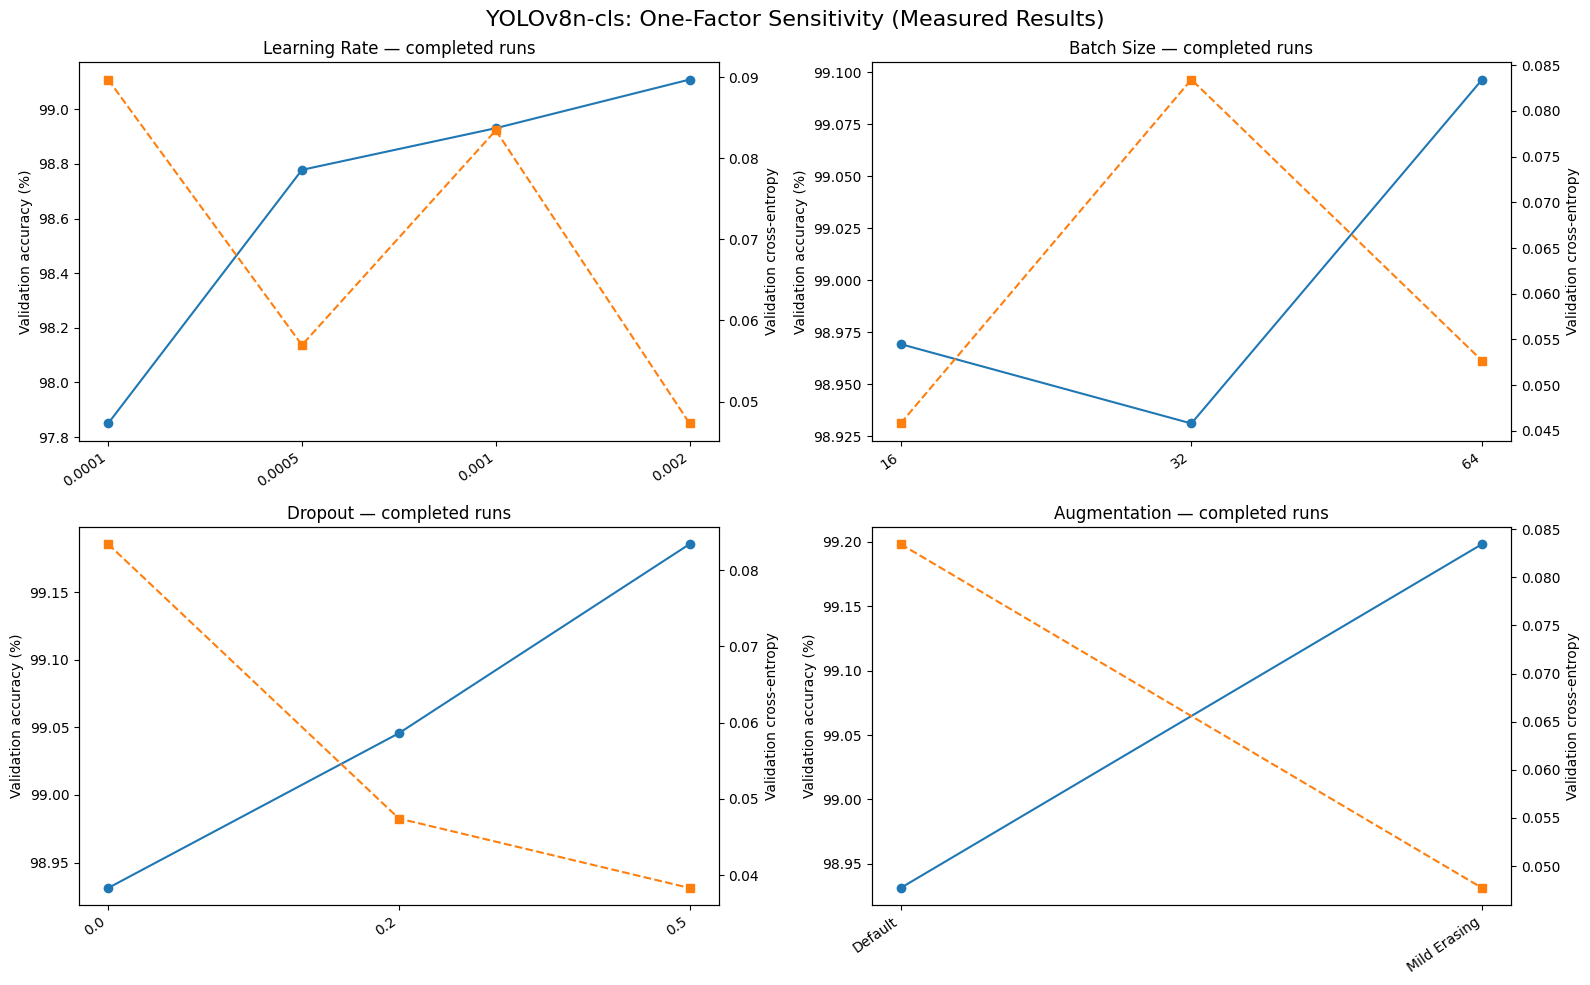

In [73]:
# Plot only measured hyperparameter group outcomes
# Load saved sensitivity results without retraining
sensitivity_yolo_df = pd.read_csv(
    YOLO_OPT_RESULTS / "YOLO_Sensitivity_Results_Partial.csv"
)

completed_search_count = len(sensitivity_yolo_df)

print(f"Loaded {completed_search_count} sensitivity comparisons")
if completed_search_count:
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    for ax, group_name in zip(axes.flat, ["Learning Rate", "Batch Size", "Dropout", "Augmentation"]):
        subset = sensitivity_yolo_df[sensitivity_yolo_df["Group"] == group_name]
        if subset.empty:
            ax.text(0.5, 0.5, "No completed runs", transform=ax.transAxes, ha="center", va="center")
            ax.set_title(group_name)
            continue
        x = np.arange(len(subset))
        ax.plot(x, subset["Validation Accuracy"].to_numpy() * 100, marker="o", label="Top-1 accuracy (%)")
        ax.set_xticks(x, subset["Tested Value"].astype(str).tolist(), rotation=35, ha="right")
        ax.set_ylabel("Validation accuracy (%)")
        ax.set_title(f"{group_name} — completed runs")
        ax2 = ax.twinx()
        ax2.plot(x, subset["Validation Loss"].to_numpy(), marker="s", linestyle="--", color="tab:orange", label="Cross-entropy")
        ax2.set_ylabel("Validation cross-entropy")
    fig.suptitle("YOLOv8n-cls: One-Factor Sensitivity (Measured Results)", fontsize=16)
    plt.tight_layout()
    fig.savefig(YOLO_OPT_RESULTS / "YOLO_Sensitivity_Accuracy_And_Loss.png", dpi=180, bbox_inches="tight")
    plt.show()
else:
    print("Sensitivity plots will appear after the first fresh experiment finishes.")

#### 7.8.2 Main Comparison

,Experiment,Accuracy (%),Validation Loss,Macro F1
0,YOLO_AUG_Mild_Erasing,99.1984,0.0477,0.9919
2,YOLO_Combined_Final,99.1856,0.0466,0.9930
7,YOLO_Baseline,98.9312,0.0834,0.9908
8,YOLO_Original_Reference,98.8548,0.0610,0.9882


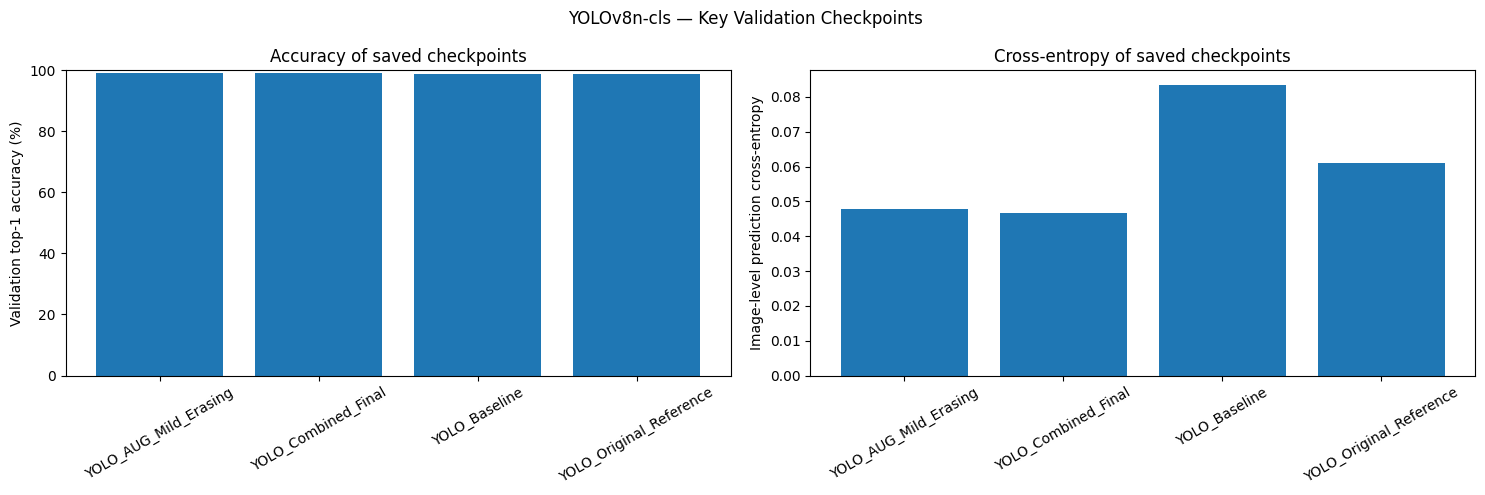

In [74]:
# Identify real completed checkpoints and plot their observed performance
comparison_names = ["YOLO_Original_Reference", "YOLO_Baseline"]
if completed_search_count:
    top_sensitivity_name = sensitivity_yolo_df.sort_values(
        ["Validation Accuracy", "Validation Loss"], ascending=[False, True]
    ).iloc[0]["Experiment"]
    comparison_names.append(top_sensitivity_name)
comparison_names.append("YOLO_Combined_Final")
comparison_names = list(dict.fromkeys(comparison_names))
comparison_df = all_yolo_results[all_yolo_results["Experiment"].isin(comparison_names)].copy()
comparison_df["Accuracy (%)"] = comparison_df["Validation Accuracy"] * 100
comparison_df.to_csv(YOLO_OPT_RESULTS / "YOLO_Key_Model_Comparison.csv", index=False)
display(comparison_df[["Experiment", "Accuracy (%)", "Validation Loss", "Macro F1"]].round(4))

if len(comparison_df):
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    axes[0].bar(comparison_df["Experiment"], comparison_df["Accuracy (%)"])
    axes[0].set_ylabel("Validation top-1 accuracy (%)")
    axes[0].set_ylim(0, 100)
    axes[0].set_title("Accuracy of saved checkpoints")
    axes[1].bar(comparison_df["Experiment"], comparison_df["Validation Loss"])
    axes[1].set_ylabel("Image-level prediction cross-entropy")
    axes[1].set_title("Cross-entropy of saved checkpoints")
    for ax in axes:
        ax.tick_params(axis="x", labelrotation=30)
    fig.suptitle("YOLOv8n-cls — Key Validation Checkpoints")
    plt.tight_layout()
    fig.savefig(YOLO_OPT_RESULTS / "YOLO_Key_Model_Comparison.png", dpi=180, bbox_inches="tight")
    plt.show()

In [75]:
# Brief interpretation based on measured YOLO results
if len(all_yolo_results):
    best_yolo_row = all_yolo_results.iloc[0]
    original_yolo_row = all_yolo_results[all_yolo_results["Experiment"] == "YOLO_Original_Reference"].iloc[0]
    change_pp = 100 * (best_yolo_row["Validation Accuracy"] - original_yolo_row["Validation Accuracy"])
    print(f"Best available YOLO: {best_yolo_row['Experiment']} — "
          f"{best_yolo_row['Validation Accuracy']:.2%} validation accuracy, "
          f"{best_yolo_row['Validation Loss']:.4f} loss.")
    print(f"Difference from original checkpoint: {change_pp:+.2f} percentage points.")
    if not yolo_search_complete:
        print("Optimization is still in progress; this is not the final comparison.")

Best available YOLO: YOLO_AUG_Mild_Erasing — 99.20% validation accuracy, 0.0477 loss.
Difference from original checkpoint: +0.34 percentage points.


### 7.9 Final YOLO Model

Select by validation Top-1 accuracy (validation loss breaks ties); preserve the original checkpoint if no optimized run is better.

In [76]:
# Preserve the original model until all experiment groups and combined training are complete
YOLO_FINAL_MODEL = YOLO_MODELS_DIR / "model2_final.pt"
yolo_selection_ready = yolo_search_complete and combined_yolo_result is not None
if not yolo_selection_ready:
    print("Final checkpoint selection is pending. Original model2.pt is preserved.")
    print("Sensitivity complete:", yolo_search_complete)
    print("Combined experiment complete:", combined_yolo_result is not None)
else:
    selected = all_yolo_results.iloc[0]
    winner_yolo_name = str(selected["Experiment"])
    selected_checkpoint = Path(str(selected["Checkpoint"]))
    assert selected_checkpoint.is_file(), f"Selected checkpoint missing: {selected_checkpoint}"
    shutil.copy2(selected_checkpoint, YOLO_FINAL_MODEL)
    pd.DataFrame([selected]).to_csv(YOLO_OPT_RESULTS / "YOLO_Final_Model_Summary.csv", index=False)
    final_yolo_probs = yolo_predict_probabilities(YOLO_FINAL_MODEL, yolo_val_df)
    final_yolo_metrics = yolo_evaluate_predictions(final_yolo_probs, YOLO_LABELS_VAL)
    assert abs(final_yolo_metrics["Validation Accuracy"] - selected["Validation Accuracy"]) < 1e-4, "Exported checkpoint validation mismatch"
    assert abs(final_yolo_metrics["Validation Loss"] - selected["Validation Loss"]) < 1e-3, "Exported checkpoint cross-entropy mismatch"
    np.save(YOLO_OPT_RESULTS / "YOLO_Final_Validation_Probabilities.npy", final_yolo_probs)
    pd.DataFrame({"ClassId": YOLO_LABELS_VAL, "Prediction": final_yolo_probs.argmax(1)}).to_csv(
        YOLO_OPT_RESULTS / "YOLO_Final_Validation_Predictions.csv", index=False
    )
    print("Selected:", winner_yolo_name)
    print("Validation top-1 accuracy:", f"{final_yolo_metrics['Validation Accuracy']:.3%}")
    print("Validation cross-entropy:", f"{final_yolo_metrics['Validation Loss']:.5f}")
    print("Saved final checkpoint:", YOLO_FINAL_MODEL)

Selected: YOLO_AUG_Mild_Erasing
Validation top-1 accuracy: 99.198%
Validation cross-entropy: 0.04773
Saved final checkpoint: /content/drive/MyDrive/ARTI502_Project/models/model2_final.pt


### 7.10 YOLO Validation Evaluation

Display precision, recall, F1, a confusion matrix, and real mistakes from the validation images.

In [77]:
# Evaluate the final checkpoint if available, otherwise inspect the original reference
if yolo_selection_ready and YOLO_FINAL_MODEL.is_file():
    diagnostic_model_name = "Final selected YOLO"
    diagnostic_checkpoint = YOLO_FINAL_MODEL
    diagnostic_probs = final_yolo_probs
else:
    diagnostic_model_name = "Original YOLO reference (provisional)"
    diagnostic_checkpoint = YOLO_ORIGINAL_MODEL
    diagnostic_probs = original_yolo_probs

val_predictions_yolo = diagnostic_probs.argmax(axis=1)
class_name_lookup_yolo = (
    yolo_val_df[["ClassId", "ClassName"]]
    .drop_duplicates(subset="ClassId").set_index("ClassId")["ClassName"].to_dict()
    if "ClassName" in yolo_val_df.columns else {c: f"Class {c}" for c in range(NUM_CLASSES)}
)
class_ids_yolo = list(range(NUM_CLASSES))
precision, recall, f1, support = precision_recall_fscore_support(
    YOLO_LABELS_VAL, val_predictions_yolo, labels=class_ids_yolo, zero_division=0
)
class_analysis_yolo = pd.DataFrame({
    "ClassId": class_ids_yolo,
    "ClassName": [class_name_lookup_yolo.get(i, f"Class {i}") for i in class_ids_yolo],
    "Support": support,
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1,
    "Errors": support - np.rint(recall * support).astype(int),
}).sort_values(["F1-score", "Support"], ascending=[True, False])
class_analysis_yolo.to_csv(YOLO_OPT_RESULTS / "YOLO_Validation_Per_Class_Metrics.csv", index=False)
report_yolo = classification_report(
    YOLO_LABELS_VAL, val_predictions_yolo, labels=class_ids_yolo, zero_division=0
)
(YOLO_OPT_RESULTS / "YOLO_Validation_Classification_Report.txt").write_text(report_yolo, encoding="utf-8")

print("Evaluated checkpoint:", diagnostic_model_name)
print("Validation top-1:", f"{accuracy_score(YOLO_LABELS_VAL, val_predictions_yolo):.3%}")
print("Validation macro-F1:", f"{f1_score(YOLO_LABELS_VAL, val_predictions_yolo, average='macro'):.4f}")
print("Total mistakes:", int((YOLO_LABELS_VAL != val_predictions_yolo).sum()), "/", len(YOLO_LABELS_VAL))
print("Worst classes by F1:")
display(class_analysis_yolo.head(8).round(4))

Evaluated checkpoint: Final selected YOLO
Validation top-1: 99.198%
Validation macro-F1: 0.9919
Total mistakes: 63 / 7859
Worst classes by F1:


,ClassId,ClassName,Support,Precision,Recall,F1-score,Errors
42,42,End no passing veh > 3.5 tons,60,1.0000,0.8333,0.9091,10
3,3,Speed limit (60km/h),270,0.9677,0.8889,0.9266,30
5,5,Speed limit (80km/h),360,0.9182,0.9972,0.9561,1
6,6,End of speed limit (80km/h),90,0.9184,1.0000,0.9574,0
38,38,Keep right,420,1.0000,0.9619,0.9806,16
0,0,Speed limit (20km/h),30,0.9677,1.0000,0.9836,0
34,34,Turn left ahead,90,0.9783,1.0000,0.9890,0
21,21,Double curve,60,1.0000,0.9833,0.9916,1


### 7.10.1 Confusion Matrix

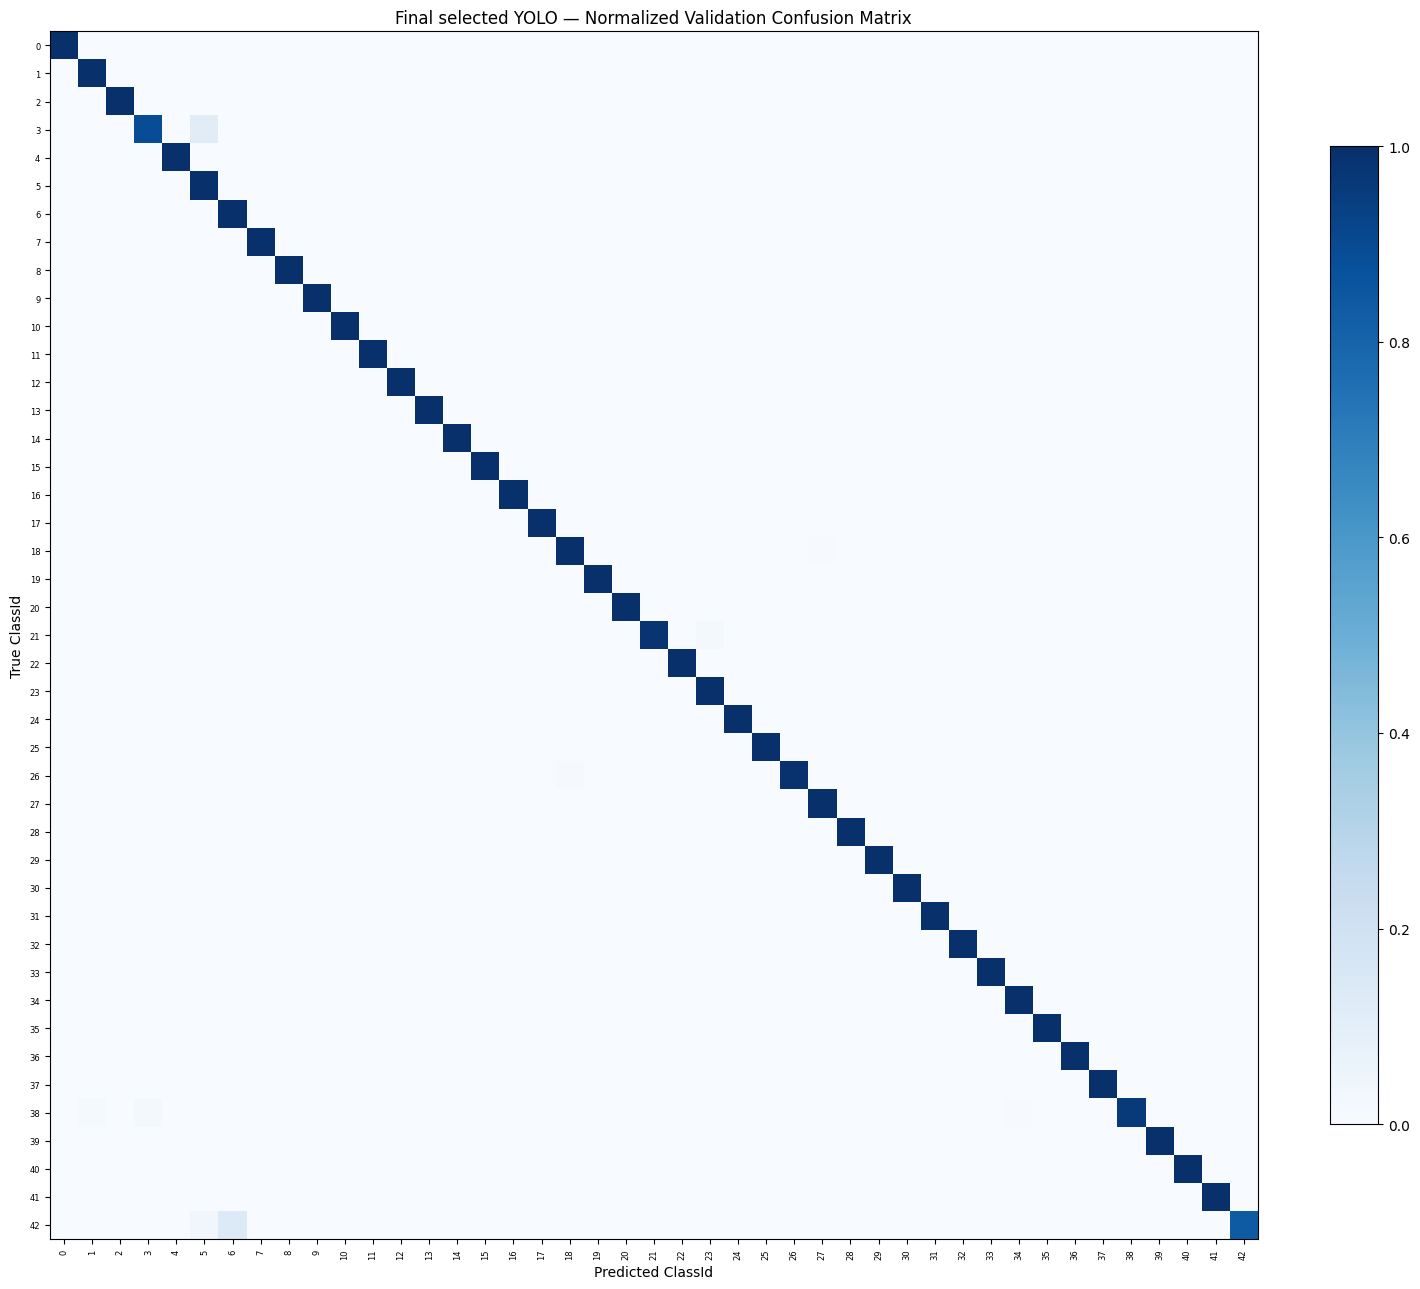

Most common specific confusions:


,True ClassId,Predicted ClassId,Count
2,3,5,30
13,42,6,8
10,38,3,8
9,38,1,5
11,38,34,2
12,42,5,2
5,18,27,1
4,7,8,1
3,5,2,1
1,2,4,1


In [78]:
# Plot row-normalized confusion to expose class-specific failure modes
cm_yolo = confusion_matrix(YOLO_LABELS_VAL, val_predictions_yolo, labels=class_ids_yolo)
cm_yolo_normalized = cm_yolo / np.maximum(cm_yolo.sum(axis=1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(15, 13))
im = ax.imshow(cm_yolo_normalized, cmap="Blues", interpolation="nearest", vmin=0, vmax=1)
ax.set_xticks(np.arange(NUM_CLASSES))
ax.set_yticks(np.arange(NUM_CLASSES))
ax.set_xticklabels(class_ids_yolo, rotation=90, fontsize=6)
ax.set_yticklabels(class_ids_yolo, fontsize=6)
ax.set_xlabel("Predicted ClassId")
ax.set_ylabel("True ClassId")
ax.set_title(f"{diagnostic_model_name} — Normalized Validation Confusion Matrix")
fig.colorbar(im, ax=ax, fraction=0.034)
plt.tight_layout()
fig.savefig(YOLO_OPT_RESULTS / "YOLO_Validation_Confusion_Matrix.png", dpi=180, bbox_inches="tight")
plt.show()

pairs = []
for t in range(NUM_CLASSES):
    for p in range(NUM_CLASSES):
        if t != p and cm_yolo[t, p] > 0:
            pairs.append({"True ClassId": t, "Predicted ClassId": p, "Count": int(cm_yolo[t, p])})
error_pairs_yolo = pd.DataFrame(pairs)
if len(error_pairs_yolo):
    error_pairs_yolo = error_pairs_yolo.sort_values("Count", ascending=False)
    error_pairs_yolo.to_csv(YOLO_OPT_RESULTS / "YOLO_Validation_Frequent_Confusions.csv", index=False)
    print("Most common specific confusions:")
    display(error_pairs_yolo.head(12))
else:
    print("No misclassification pairs were detected.")

### 7.10.2 Misclassified Image Examples

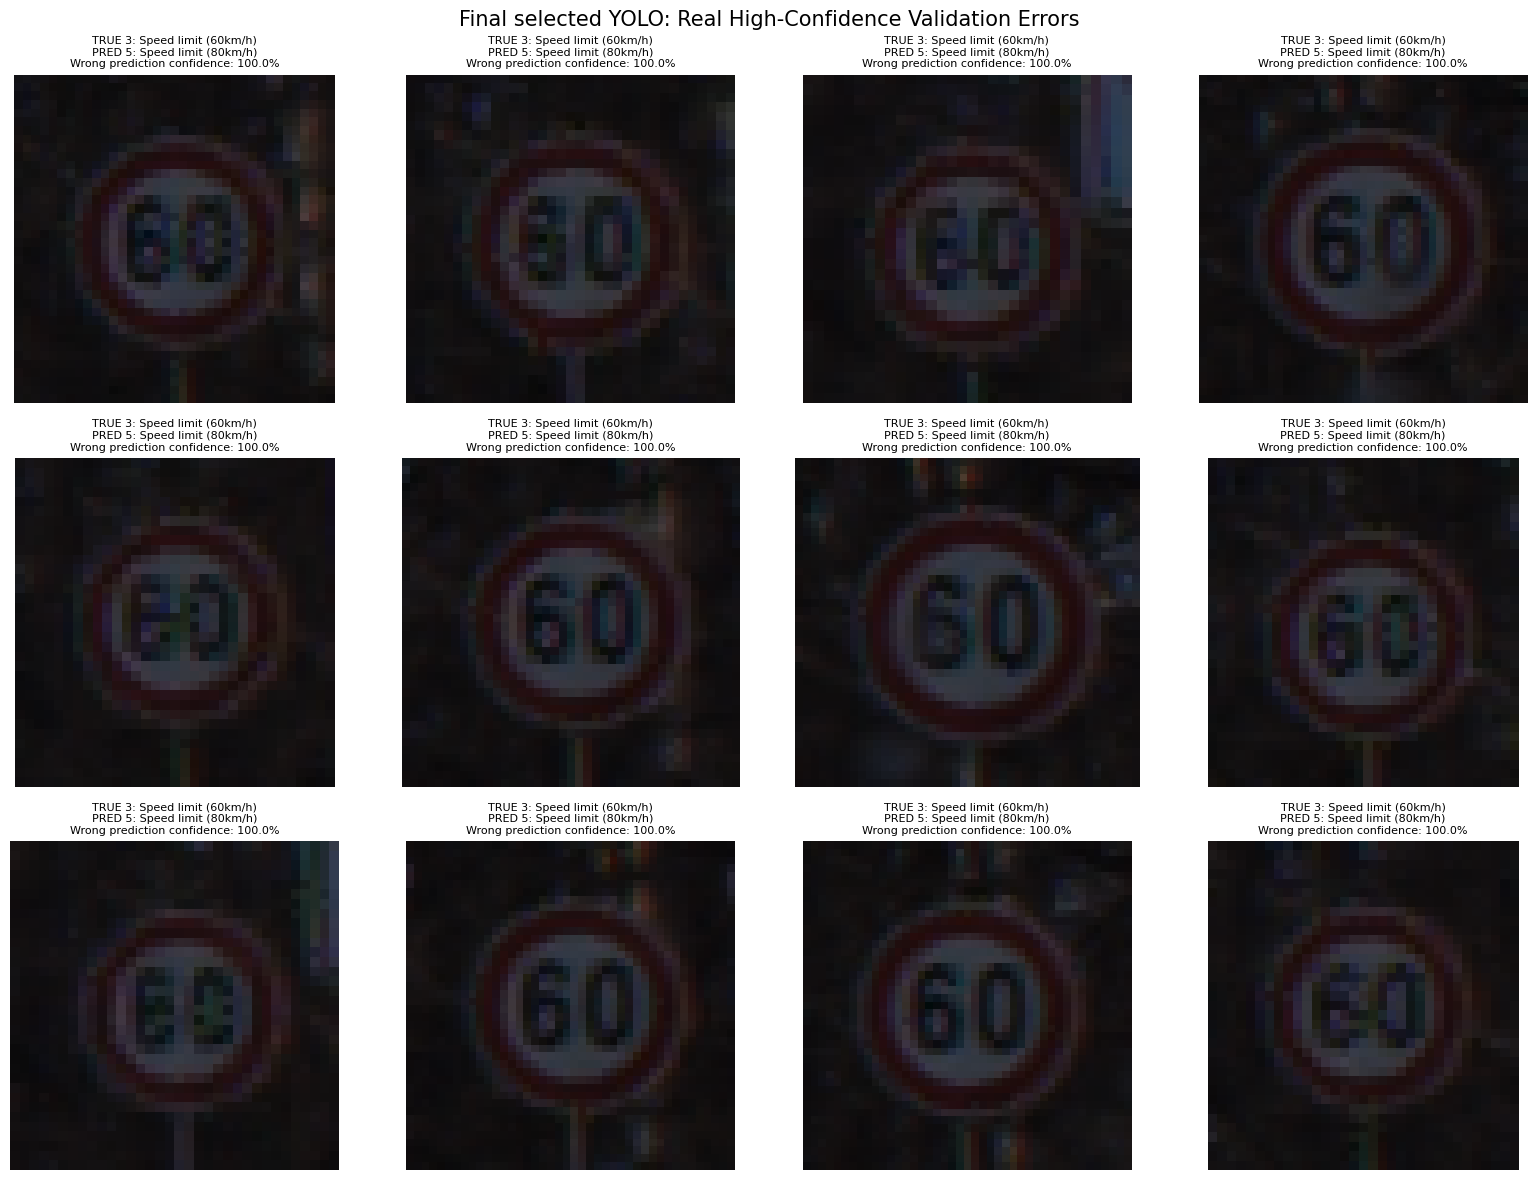

In [79]:
# Display real misclassified validation samples with descriptive labels
incorrect_indices_yolo = np.flatnonzero(YOLO_LABELS_VAL != val_predictions_yolo)
if len(incorrect_indices_yolo) > 0:
    wrong_confidence = diagnostic_probs[incorrect_indices_yolo].max(axis=1)
    incorrect_indices_yolo = incorrect_indices_yolo[np.argsort(-wrong_confidence)]

    details = pd.DataFrame({
        "Validation Row": incorrect_indices_yolo,
        "Image Path": yolo_val_df.iloc[incorrect_indices_yolo]["Path"].to_numpy(),
        "True ClassId": YOLO_LABELS_VAL[incorrect_indices_yolo],
        "Predicted ClassId": val_predictions_yolo[incorrect_indices_yolo],
        "Predicted Confidence": diagnostic_probs[incorrect_indices_yolo].max(axis=1),
    })
    details["True ClassName"] = details["True ClassId"].map(class_name_lookup_yolo)
    details["Predicted ClassName"] = details["Predicted ClassId"].map(class_name_lookup_yolo)
    details.to_csv(YOLO_OPT_RESULTS / "YOLO_Validation_Error_Examples.csv", index=False)

    show_indices = incorrect_indices_yolo[:12]
    fig, axes = plt.subplots(3, 4, figsize=(16, 12))
    for ax, idx in zip(axes.flat, show_indices):
        item = yolo_val_df.iloc[int(idx)]
        with Image.open(YOLO_IMAGE_ROOT / str(item["Path"])) as picture:
            ax.imshow(picture.convert("RGB"))
        truth, prediction = int(YOLO_LABELS_VAL[idx]), int(val_predictions_yolo[idx])
        ax.set_title(
            f"TRUE {truth}: {class_name_lookup_yolo.get(truth, '')[:25]}\n"
            f"PRED {prediction}: {class_name_lookup_yolo.get(prediction, '')[:25]}\n"
            f"Wrong prediction confidence: {diagnostic_probs[idx, prediction]:.1%}",
            fontsize=8
        )
        ax.axis("off")
    for ax in axes.flat[len(show_indices):]:
        ax.axis("off")
    fig.suptitle(f"{diagnostic_model_name}: Real High-Confidence Validation Errors", fontsize=15)
    plt.tight_layout()
    fig.savefig(YOLO_OPT_RESULTS / "YOLO_Validation_Misclassified_Images.png", dpi=180, bbox_inches="tight")
    plt.show()
else:
    print("No incorrect validation predictions found.")

----